# Data Mining Coursework
# Descriptive, Predictive, and Text Analytics for Airline Customer Reviews

In [1]:
!pip install contractions -q
!pip install textblob wordcloud --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 12.2 MB/s eta 0:00:00


In [2]:
# ── CORE DATA HANDLING ───────────────────────────────────────
import pandas as pd
import numpy as np

# ── VISUALISATION ────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from wordcloud import WordCloud

# ── TEXT PROCESSING ──────────────────────────────────────────
import re
import string
import nltk
import contractions
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk.tokenize import TreebankWordTokenizer
from collections import Counter

# Download required NLTK assets
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('vader_lexicon')

# ── SENTIMENT ANALYSIS ───────────────────────────────────────
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from textblob import TextBlob

# ── FEATURE ENGINEERING ──────────────────────────────────────
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

# ── MACHINE LEARNING ─────────────────────────────────────────
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# ── EVALUATION METRICS ───────────────────────────────────────
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# ── FEATURE COMBINATION ──────────────────────────────────────
from scipy.sparse import hstack, csr_matrix

print("✅ All libraries imported successfully!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


✅ All libraries imported successfully!


In [3]:
# ── REPRODUCIBILITY ──────────────────────────────────────────
import random
SEED = 40481810
random.seed(SEED)
np.random.seed(SEED)

# ── DISPLAY SETTINGS ─────────────────────────────────────────
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)
sns.set_theme(style="whitegrid", palette="muted")

print(f"✅ Seed set to {SEED}")

✅ Seed set to 40481810


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# --- Load the dataset from Google Drive ---
file_path = '/content/drive/MyDrive/airline_reviews.csv'  # update to where you saved the dataset
df = pd.read_csv(file_path)

In [6]:
# --- Shape ---
print("=" * 50)
print("DATASET SHAPE")
print("=" * 50)
print(f"Rows: {df.shape[0]},  Columns: {df.shape[1]}")

# --- Column names & data types ---
print("\n" + "=" * 50)
print("COLUMN NAMES & DATA TYPES")
print("=" * 50)
print(df.dtypes)

# --- First 5 rows ---
print("\n" + "=" * 50)
print("FIRST 5 ROWS")
print("=" * 50)
df.head()


DATASET SHAPE
Rows: 23171,  Columns: 20

COLUMN NAMES & DATA TYPES
ID                          int64
Airline Name               object
Overall_Rating             object
Review_Title               object
Review Date                object
Verified                     bool
Review                     object
Aircraft                   object
Type Of Traveller          object
Seat Type                  object
Route                      object
Date Flown                 object
Seat Comfort              float64
Cabin Staff Service       float64
Food & Beverages          float64
Ground Service            float64
Inflight Entertainment    float64
Wifi & Connectivity       float64
Value For Money           float64
Recommended                object
dtype: object

FIRST 5 ROWS


,ID,Airline Name,Overall_Rating,Review_Title,Review Date,Verified,Review,Aircraft,Type Of Traveller,Seat Type,Route,Date Flown,Seat Comfort,Cabin Staff Service,Food & Beverages,Ground Service,Inflight Entertainment,Wifi & Connectivity,Value For Money,Recommended
0,0,AB Aviation,9,"""pretty decent airline""",11th November 2019,True,"Moroni to Moheli. Turned out to be a pretty decent airline. Online booking worked well, checki...",NaN,Solo Leisure,Economy Class,Moroni to Moheli,Nov-19,4.0,5.0,4.0,4.0,NaN,NaN,3.0,yes
1,1,AB Aviation,1,"""Not a good airline""",25th June 2019,True,Moroni to Anjouan. It is a very small airline. My ticket advised me to turn up at 0800hrs which...,E120,Solo Leisure,Economy Class,Moroni to Anjouan,Jun-19,2.0,2.0,1.0,1.0,NaN,NaN,2.0,no
2,2,AB Aviation,1,"""flight was fortunately short""",25th June 2019,True,Anjouan to Dzaoudzi. A very small airline and the only airline based in Comoros. Check-in was ...,Embraer E120,Solo Leisure,Economy Class,Anjouan to Dzaoudzi,Jun-19,2.0,1.0,1.0,1.0,NaN,NaN,2.0,no
3,3,Adria Airways,1,"""I will never fly again with Adria""",28th September 2019,False,Please do a favor yourself and do not fly with Adria. On the route from Munich to Pristina in ...,NaN,Solo Leisure,Economy Class,Frankfurt to Pristina,Sep-19,1.0,1.0,NaN,1.0,NaN,NaN,1.0,no
4,4,Adria Airways,1,"""it ruined our last days of holidays""",24th September 2019,True,Do not book a flight with this airline! My friend and I should have returned from Sofia to Amst...,NaN,Couple Leisure,Economy Class,Sofia to Amsterdam via Ljubljana,Sep-19,1.0,1.0,1.0,1.0,1.0,1.0,1.0,no


In [7]:
# ============================================================
# PART 2: Missing Values & Data Quality Check
# ============================================================

# --- Missing values count & percentage ---
print("=" * 50)
print("MISSING VALUES")
print("=" * 50)
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df) * 100).round(2)
})
print(missing[missing['Missing Count'] > 0].sort_values('Missing %', ascending=False))

# --- Check Recommended column unique values ---
print("\n" + "=" * 50)
print("TARGET VARIABLE: Recommended")
print("=" * 50)
print(df['Recommended'].value_counts())

# --- Check Overall_Rating unique values (it came as string) ---
print("\n" + "=" * 50)
print("OVERALL RATING - UNIQUE VALUES (first 20)")
print("=" * 50)
print(sorted(df['Overall_Rating'].dropna().unique())[:20])

MISSING VALUES
                        Missing Count  Missing %
Wifi & Connectivity             17251      74.45
Aircraft                        16042      69.23
Inflight Entertainment          12342      53.26
Food & Beverages                 8671      37.42
Ground Service                   4793      20.69
Cabin Staff Service              4260      18.39
Seat Comfort                     4155      17.93
Route                            3828      16.52
Date Flown                       3754      16.20
Type Of Traveller                3738      16.13
Seat Type                        1096       4.73
Value For Money                  1066       4.60

TARGET VARIABLE: Recommended
Recommended
no     15364
yes     7807
Name: count, dtype: int64

OVERALL RATING - UNIQUE VALUES (first 20)
['1', '2', '3', '4', '5', '6', '7', '8', '9', 'n']


In [8]:
# ------Checking unique values for other columns as well----------
print(sorted(df['Recommended'].dropna().unique()))
print(sorted(df['Type Of Traveller'].dropna().unique()))
print(sorted(df['Seat Type'].dropna().unique()))

['no', 'yes']
['Business', 'Couple Leisure', 'Family Leisure', 'Solo Leisure']
['Business Class', 'Economy Class', 'First Class', 'Premium Economy']


In [9]:
# ============================================================
# PRE-CLEANING: Descriptive Statistics Before Imputation
# ============================================================

numerical_cols_raw = ['Seat Comfort', 'Cabin Staff Service', 'Food & Beverages',
                      'Ground Service', 'Inflight Entertainment', 'Value For Money']

print("=" * 50)
print("PRE-CLEANING DESCRIPTIVE STATISTICS")
print("=" * 50)
pre_stats = df[numerical_cols_raw].agg(['mean', 'median', 'std']).round(2)
print(pre_stats)

PRE-CLEANING DESCRIPTIVE STATISTICS
        Seat Comfort  Cabin Staff Service  Food & Beverages  Ground Service  \
mean            2.62                 2.87              2.55            2.35   
median          3.00                 3.00              2.00            1.00   
std             1.46                 1.60              1.53            1.60   

        Inflight Entertainment  Value For Money  
mean                      2.18             2.45  
median                    2.00             2.00  
std                       1.49             1.59  


In [10]:
# ============================================================
# PART 3: Data Cleaning
# ============================================================


# --- Step 1: Fix Overall_Rating ---
# 'n' is a data entry error, convert it to NaN then to numeric
df['Overall_Rating'] = pd.to_numeric(df['Overall_Rating'], errors='coerce')

print("=" * 50)
print("OVERALL RATING - AFTER CLEANING")
print("=" * 50)
print(f"Missing values in Overall_Rating: {df['Overall_Rating'].isnull().sum()}")
print(f"Data type now: {df['Overall_Rating'].dtype}")
print(f"Min: {df['Overall_Rating'].min()},  Max: {df['Overall_Rating'].max()}")

# --- Step 2: Fix Recommended column ---
# Convert 'yes'/'no' to 1/0 for modelling
df['Recommended'] = df['Recommended'].map({'yes': 1, 'no': 0})

print("\n" + "=" * 50)
print("RECOMMENDED - AFTER CLEANING")
print("=" * 50)
print(df['Recommended'].value_counts())

# --- Step 3: Drop extremely high missing columns ---
# Aircraft (69%) and Wifi & Connectivity (74%) are too sparse to be useful
cols_to_drop = ['Aircraft', 'Wifi & Connectivity']
df.drop(columns=cols_to_drop, inplace=True)

print("\n" + "=" * 50)
print("COLUMNS DROPPED")
print("=" * 50)
print(f"Dropped: {cols_to_drop}")
print(f"Remaining columns: {df.shape[1]}")

# --- Step 4: Impute missing numerical ratings with median ---
# We use MEDIAN not mean because ratings are on a scale (1-5)
# and median is more robust to outliers
numerical_cols = ['Seat Comfort', 'Cabin Staff Service', 'Food & Beverages',
                  'Ground Service', 'Inflight Entertainment', 'Value For Money']

for col in numerical_cols:
    df[col] = df.groupby('Airline Name')[col].transform(
        lambda x: x.fillna(x.median())
    )
    df[col].fillna(df[col].median(), inplace=True)
    print(f"'{col}' missing after imputation: {df[col].isnull().sum()}")

# --- Step 5: Final missing value check ---
print("\n" + "=" * 50)
print("MISSING VALUES AFTER CLEANING")
print("=" * 50)
missing_after = df.isnull().sum()
print(missing_after[missing_after > 0])

OVERALL RATING - AFTER CLEANING
Missing values in Overall_Rating: 842
Data type now: float64
Min: 1.0,  Max: 9.0

RECOMMENDED - AFTER CLEANING
Recommended
0    15364
1     7807
Name: count, dtype: int64

COLUMNS DROPPED
Dropped: ['Aircraft', 'Wifi & Connectivity']
Remaining columns: 18


/tmp/ipykernel_7919/3935590424.py:47: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)
/tmp/ipykernel_7919/3935590424.py:47: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try 

'Seat Comfort' missing after imputation: 0
'Cabin Staff Service' missing after imputation: 0


/tmp/ipykernel_7919/3935590424.py:47: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)
/tmp/ipykernel_7919/3935590424.py:47: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try 

'Food & Beverages' missing after imputation: 0
'Ground Service' missing after imputation: 0
'Inflight Entertainment' missing after imputation: 0
'Value For Money' missing after imputation: 0

MISSING VALUES AFTER CLEANING
Overall_Rating        842
Type Of Traveller    3738
Seat Type            1096
Route                3828
Date Flown           3754
dtype: int64


/tmp/ipykernel_7919/3935590424.py:47: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)
/tmp/ipykernel_7919/3935590424.py:47: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try 

In [11]:
# ============================================================
# Handle Remaining Missing Values
# ============================================================

categorical_missing = ['Type Of Traveller', 'Seat Type', 'Route', 'Date Flown']

for col in categorical_missing:
    df[col] = df[col].fillna('Unknown')
    print(f"'{col}' missing now: {df[col].isnull().sum()}")

print("\n" + "=" * 50)
print("FINAL DATASET SUMMARY")
print("=" * 50)
print(f"Shape: {df.shape}")
print(f"Overall_Rating missing: {df['Overall_Rating'].isnull().sum()}")
print(f"\nRemaining missing values:")
remaining = df.isnull().sum()
print(remaining[remaining > 0])
print("\nData types:")
print(df.dtypes)

'Type Of Traveller' missing now: 0
'Seat Type' missing now: 0
'Route' missing now: 0
'Date Flown' missing now: 0

FINAL DATASET SUMMARY
Shape: (23171, 18)
Overall_Rating missing: 842

Remaining missing values:
Overall_Rating    842
dtype: int64

Data types:
ID                          int64
Airline Name               object
Overall_Rating            float64
Review_Title               object
Review Date                object
Verified                     bool
Review                     object
Type Of Traveller          object
Seat Type                  object
Route                      object
Date Flown                 object
Seat Comfort              float64
Cabin Staff Service       float64
Food & Beverages          float64
Ground Service            float64
Inflight Entertainment    float64
Value For Money           float64
Recommended                 int64
dtype: object


In [12]:
# ============================================================
# PART 4: Descriptive Statistics — Numerical Features
# ============================================================

num_cols = ['Overall_Rating', 'Seat Comfort', 'Cabin Staff Service',
                  'Food & Beverages', 'Ground Service', 'Inflight Entertainment',
                  'Value For Money']

# --- Descriptive Statistics ---
print("=" * 50)
print("DESCRIPTIVE STATISTICS")
print("=" * 50)
print(df[num_cols].describe().round(2))

DESCRIPTIVE STATISTICS
       Overall_Rating  Seat Comfort  Cabin Staff Service  Food & Beverages  \
count        22329.00      23171.00             23171.00          23171.00   
mean             3.14          2.61                 2.86              2.35   
std              2.88          1.40                 1.53              1.40   
min              1.00          0.00                 0.00              0.00   
25%              1.00          1.00                 1.00              1.00   
50%              1.00          3.00                 3.00              2.00   
75%              5.00          4.00                 4.00              3.00   
max              9.00          5.00                 5.00              5.00   

       Ground Service  Inflight Entertainment  Value For Money  
count        23171.00                23171.00         23171.00  
mean             2.32                    1.76             2.47  
std              1.52                    1.27             1.58  
min           

In [13]:
# --- Class Distribution ---
print("\n" + "=" * 50)
print("TARGET VARIABLE DISTRIBUTION")
print("=" * 50)
print(df['Recommended'].value_counts())
print(f"\nClass ratio (0:1): {df['Recommended'].value_counts()[0] / df['Recommended'].value_counts()[1]:.2f}")


TARGET VARIABLE DISTRIBUTION
Recommended
0    15364
1     7807
Name: count, dtype: int64

Class ratio (0:1): 1.97


In [14]:
# ============================================================
# PART 4: Skewness Check
# ============================================================

print("=" * 50)
print("SKEWNESS OF NUMERICAL FEATURES")
print("=" * 50)
print(df[numerical_cols].skew().round(3))

print("\n" + "=" * 50)
print("INTERPRETATION KEY")
print("=" * 50)
print("Between -0.5 and 0.5  = Approximately symmetric")
print("Between 0.5 and 1.0   = Moderately right skewed")
print("Above 1.0             = Highly right skewed")
print("Between -1.0 and -0.5 = Moderately left skewed")
print("Below -1.0            = Highly left skewed")

SKEWNESS OF NUMERICAL FEATURES
Seat Comfort              0.242
Cabin Staff Service       0.075
Food & Beverages          0.530
Ground Service            0.638
Inflight Entertainment    1.130
Value For Money           0.451
dtype: float64

INTERPRETATION KEY
Between -0.5 and 0.5  = Approximately symmetric
Between 0.5 and 1.0   = Moderately right skewed
Above 1.0             = Highly right skewed
Between -1.0 and -0.5 = Moderately left skewed
Below -1.0            = Highly left skewed


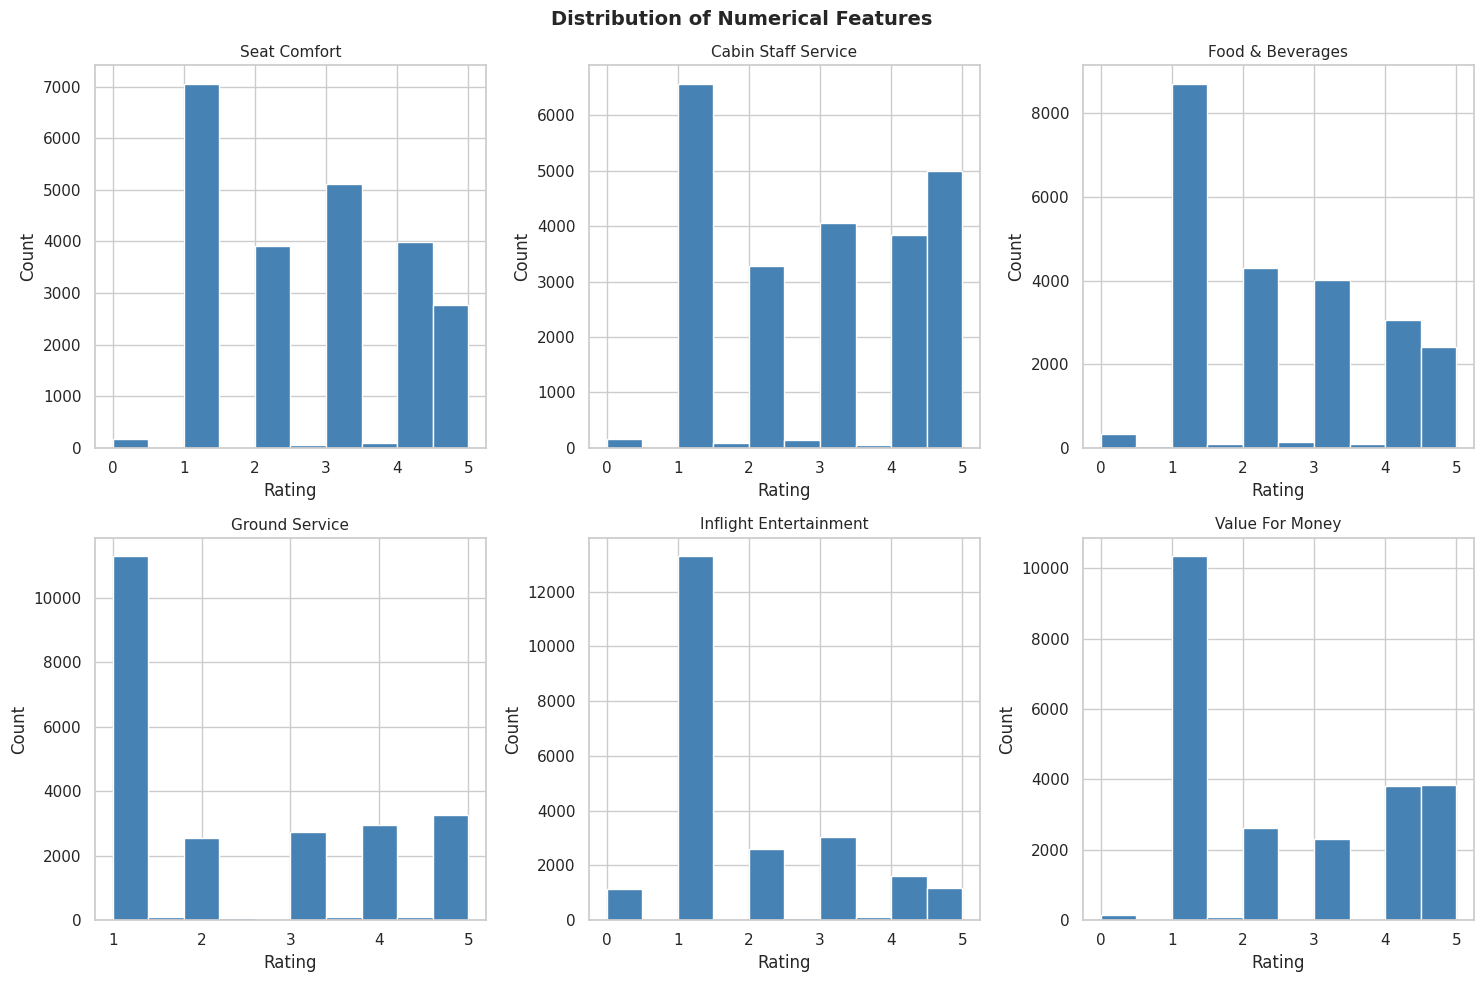

In [15]:
# ============================================================
# Visualisations — Distribution of Numerical Features
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    axes[i].hist(df[col].dropna(), bins=10, color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel('Rating')
    axes[i].set_ylabel('Count')

plt.suptitle('Distribution of Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

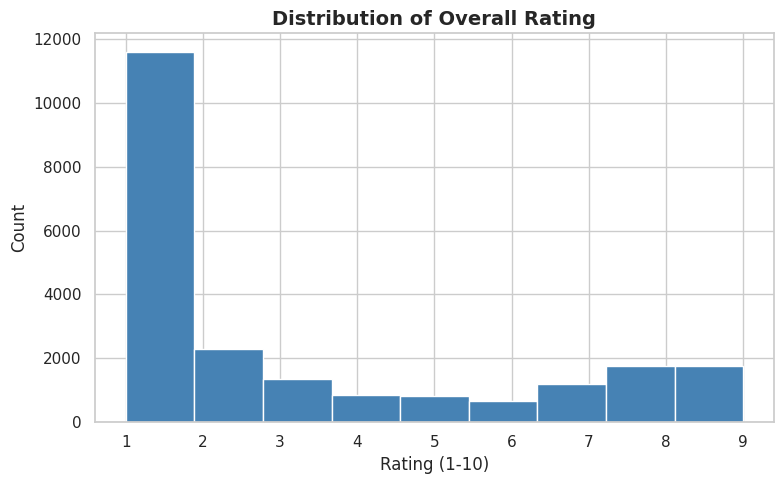

In [16]:
# ============================================================
# Overall Rating Distribution
# ============================================================

plt.figure(figsize=(8, 5))
plt.hist(df['Overall_Rating'].dropna(), bins=9, color='steelblue', edgecolor='white')
plt.title('Distribution of Overall Rating', fontsize=14, fontweight='bold')
plt.xlabel('Rating (1-10)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

SPEARMAN CORRELATION MATRIX
                        Seat Comfort  Cabin Staff Service  Food & Beverages  \
Seat Comfort                    1.00                 0.76              0.66   
Cabin Staff Service             0.76                 1.00              0.69   
Food & Beverages                0.66                 0.69              1.00   
Ground Service                  0.66                 0.67              0.57   
Inflight Entertainment          0.38                 0.35              0.46   
Value For Money                 0.70                 0.69              0.61   
Recommended                     0.63                 0.64              0.56   

                        Ground Service  Inflight Entertainment  \
Seat Comfort                      0.66                    0.38   
Cabin Staff Service               0.67                    0.35   
Food & Beverages                  0.57                    0.46   
Ground Service                    1.00                    0.29   
Inflight 

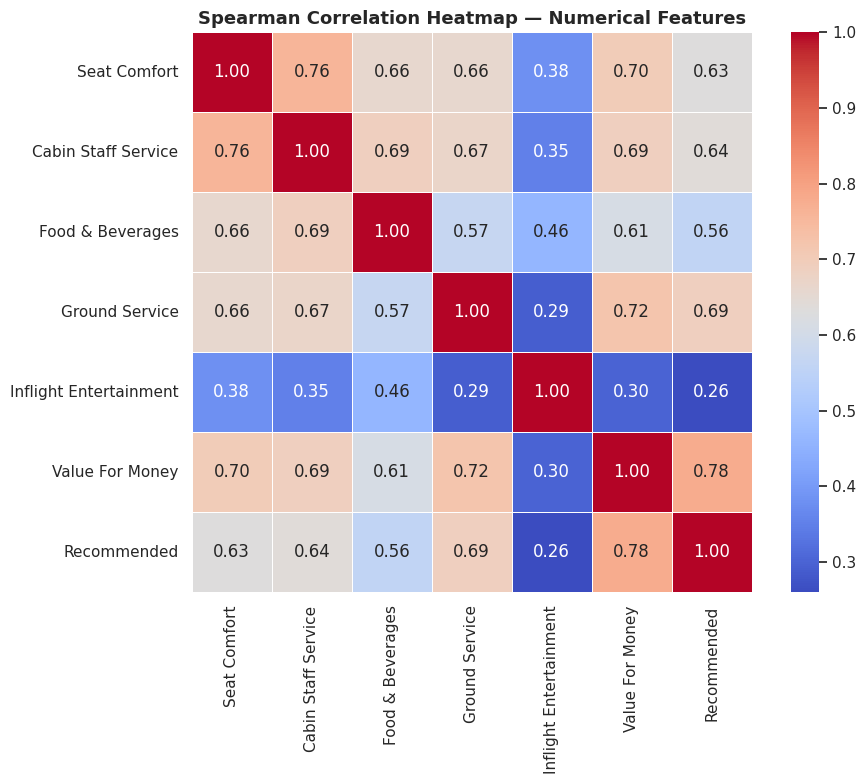

In [17]:
# ============================================================
# PART 4a: Spearman Correlation (replacing Pearson)
# ============================================================

spearman_corr = df[numerical_cols + ['Recommended']].corr(method='spearman').round(2)

print("=" * 50)
print("SPEARMAN CORRELATION MATRIX")
print("=" * 50)
print(spearman_corr)

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(spearman_corr,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            linewidths=0.5,
            square=True)
plt.title('Spearman Correlation Heatmap — Numerical Features',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

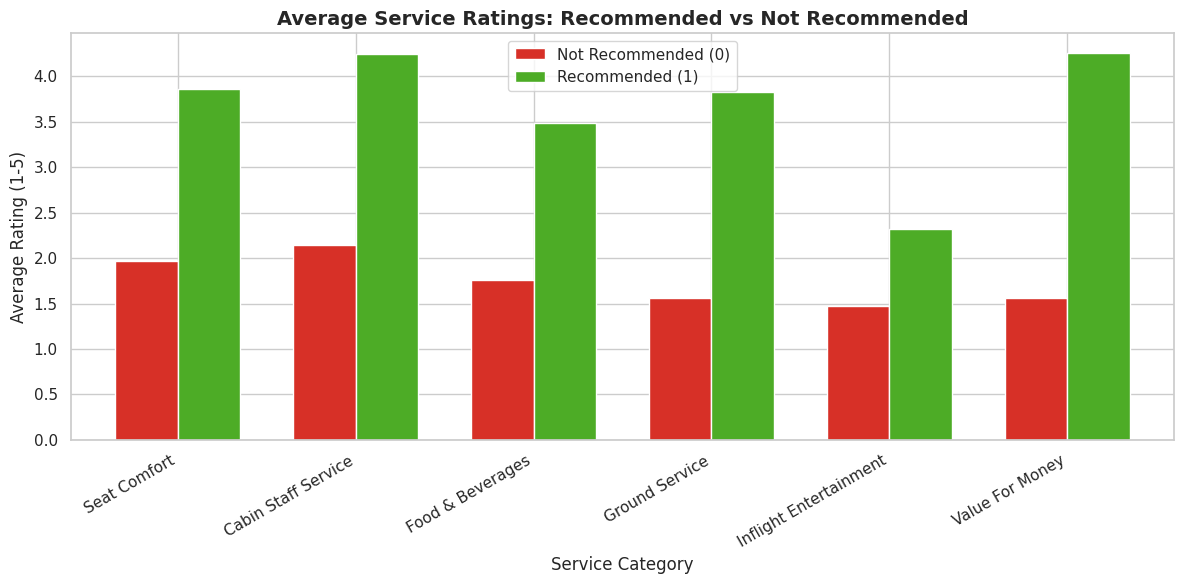

             Seat Comfort  Cabin Staff Service  Food & Beverages  \
Recommended                                                        
0                    1.97                 2.15              1.76   
1                    3.86                 4.25              3.49   

             Ground Service  Inflight Entertainment  Value For Money  
Recommended                                                           
0                      1.56                    1.47             1.56  
1                      3.83                    2.32             4.26  


In [18]:
# ============================================================
# Visualisation 3 — Average Ratings by Recommendation
# ============================================================

#Used AI to debug an error here
avg_ratings = df.groupby('Recommended')[numerical_cols].mean().round(2)

avg_ratings.T.plot(kind='bar', figsize=(12, 6),
                   color=['#d73027', '#4dac26'],
                   edgecolor='white', width=0.7)

plt.title('Average Service Ratings: Recommended vs Not Recommended',
          fontsize=14, fontweight='bold')
plt.xlabel('Service Category')
plt.ylabel('Average Rating (1-5)')
plt.xticks(rotation=30, ha='right')
plt.legend(['Not Recommended (0)', 'Recommended (1)'], fontsize=11)
plt.tight_layout()
plt.show()

print(avg_ratings)

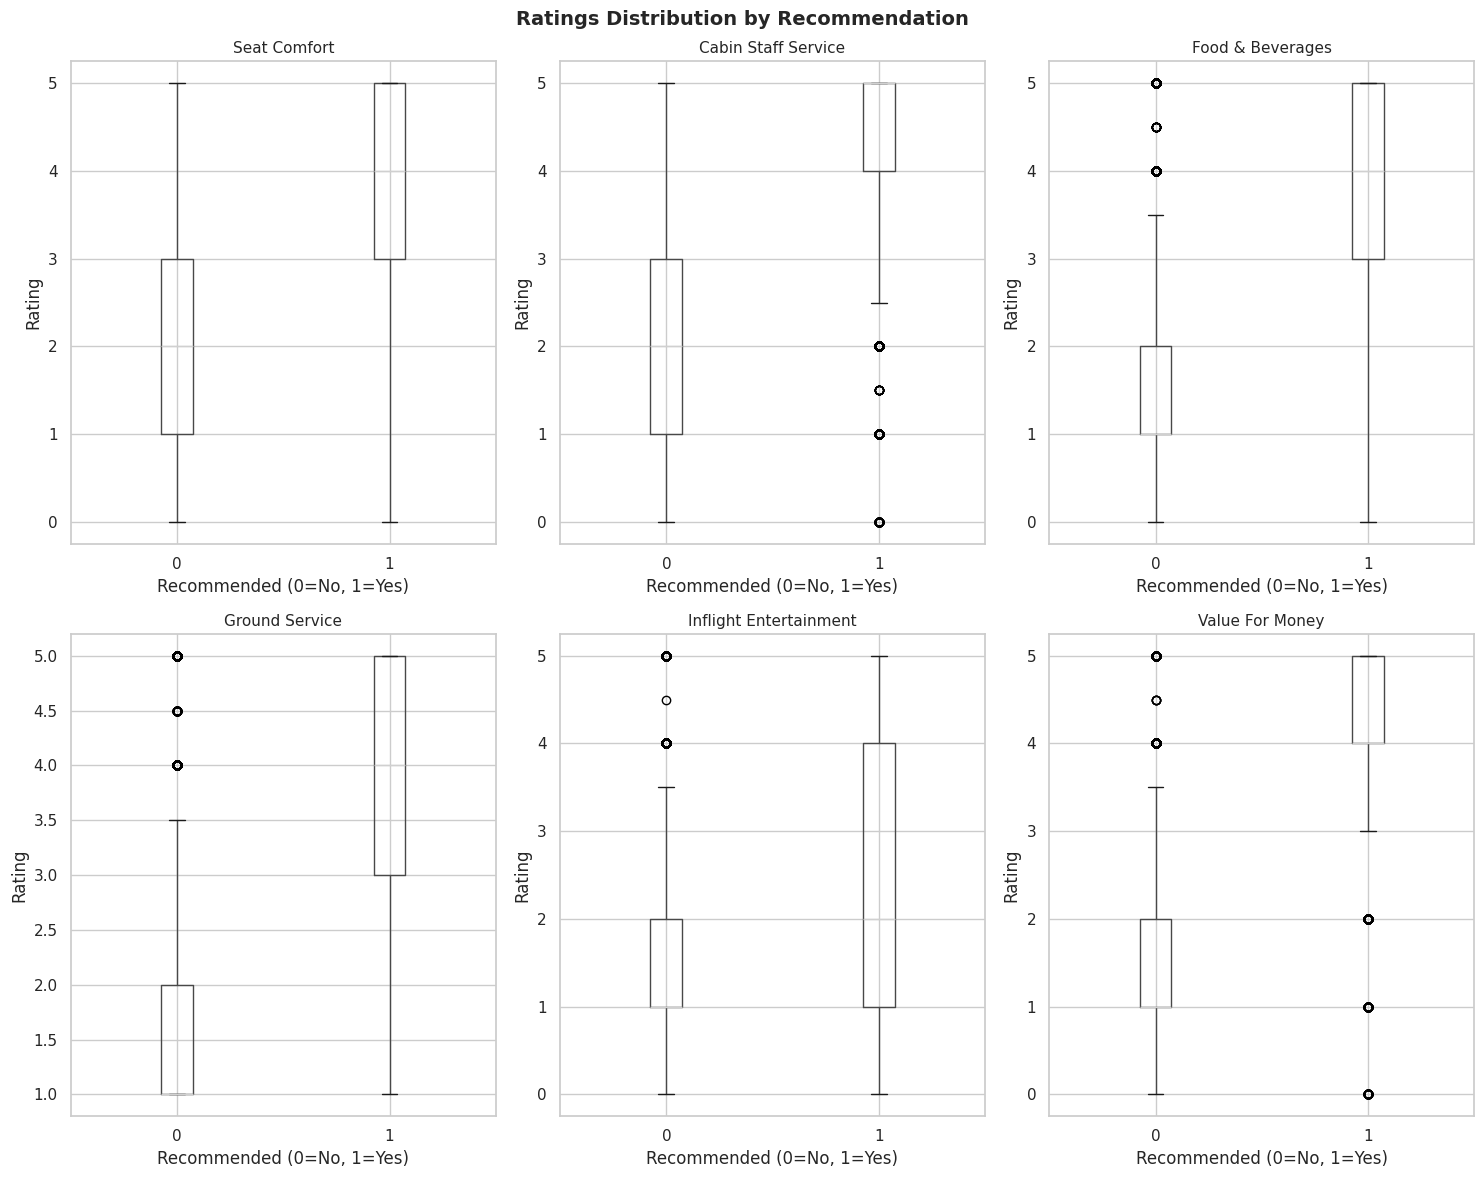

In [19]:
# ============================================================
# Visualisation 2 — Box Plots by Recommendation
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    df.boxplot(column=col, by='Recommended', ax=axes[i])
    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel('Recommended (0=No, 1=Yes)')
    axes[i].set_ylabel('Rating')

plt.suptitle('Ratings Distribution by Recommendation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

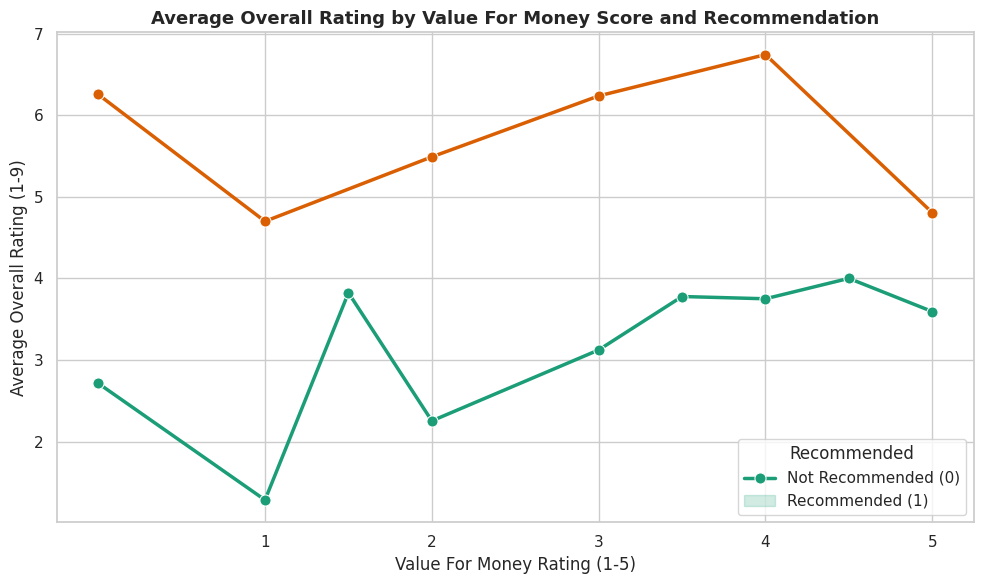

In [20]:
# ============================================================
# PART 4a: Visualisation 6 — Value For Money vs Recommendation
# Mean Overall Rating per Value For Money Rating
# ============================================================

vfm_avg = df.groupby(['Value For Money', 'Recommended'])['Overall_Rating'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.lineplot(data=vfm_avg, x='Value For Money', y='Overall_Rating',
             hue='Recommended', palette='Dark2',
             marker='o', linewidth=2.5, markersize=8)
plt.title('Average Overall Rating by Value For Money Score and Recommendation',
          fontsize=13, fontweight='bold')
plt.xlabel('Value For Money Rating (1-5)')
plt.ylabel('Average Overall Rating (1-9)')
plt.xticks([1, 2, 3, 4, 5])
plt.legend(title='Recommended', labels=['Not Recommended (0)', 'Recommended (1)'])
plt.tight_layout()
plt.show()

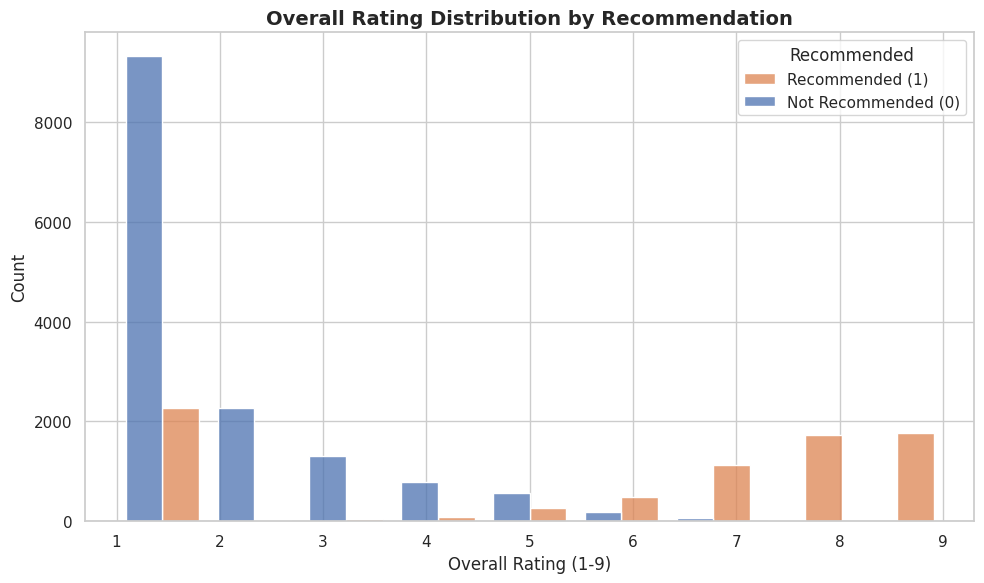

In [21]:
# ============================================================
# PART 4a: Visualisation 5 — Overall Rating Distribution
# by Recommendation
# ============================================================

plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Overall_Rating', hue='Recommended',
             multiple='dodge', bins=9, palette='deep',
             shrink=0.8)
plt.title('Overall Rating Distribution by Recommendation',
          fontsize=14, fontweight='bold')
plt.xlabel('Overall Rating (1-9)')
plt.ylabel('Count')
plt.legend(title='Recommended', labels=['Recommended (1)', 'Not Recommended (0)'])
plt.tight_layout()
plt.show()

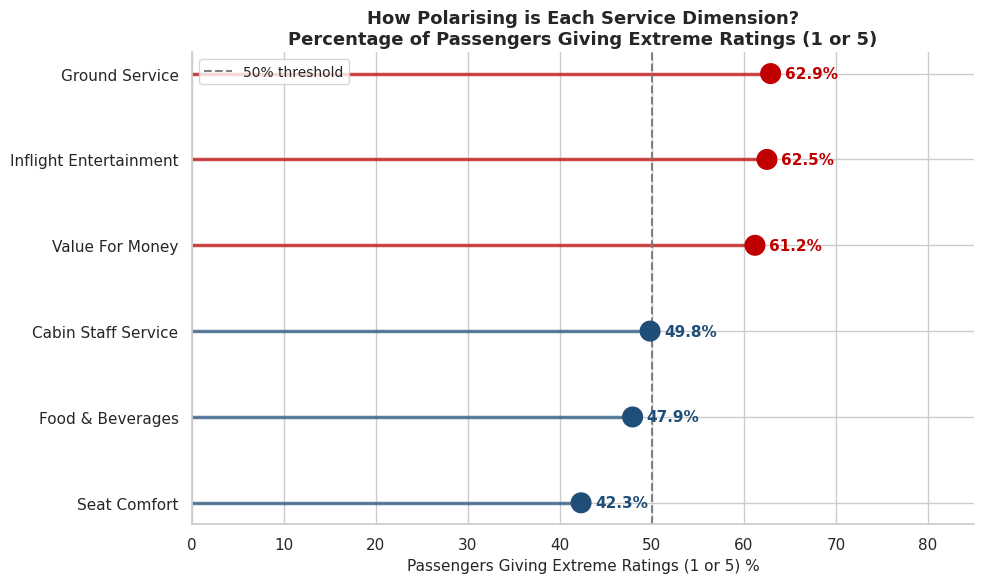

              Category  Extreme %
        Ground Service       62.9
Inflight Entertainment       62.5
       Value For Money       61.2
   Cabin Staff Service       49.8
      Food & Beverages       47.9
          Seat Comfort       42.3


In [22]:
# ============================================================
# PART 4a: Visualisation 11 — Extreme Rating % per Category
# ============================================================

extreme_pct = {}
for col in numerical_cols:
    extreme = ((df[col] == 1) | (df[col] == 5)).sum()
    total = df[col].notna().sum()
    extreme_pct[col] = round(extreme / total * 100, 1)

extreme_df = pd.DataFrame(list(extreme_pct.items()),
                          columns=['Category', 'Extreme %']).sort_values(
                          'Extreme %', ascending=True)

colors = ['#C00000' if v >= 60 else '#1F4E79' for v in extreme_df['Extreme %']]

fig, ax = plt.subplots(figsize=(10, 6))

ax.hlines(y=extreme_df['Category'], xmin=0,
          xmax=extreme_df['Extreme %'],
          color=colors, linewidth=2.5, alpha=0.7)

ax.scatter(extreme_df['Extreme %'], extreme_df['Category'],
           color=colors, s=200, zorder=5)

for _, row in extreme_df.iterrows():
    color = '#C00000' if row['Extreme %'] >= 60 else '#1F4E79'
    ax.annotate(f"{row['Extreme %']}%",
                (row['Extreme %'], row['Category']),
                textcoords='offset points',
                xytext=(10, 0), va='center',
                fontsize=11, fontweight='bold', color=color)

ax.axvline(x=50, color='grey', linestyle='--',
           linewidth=1.5, label='50% threshold')
ax.set_xlabel('Passengers Giving Extreme Ratings (1 or 5) %', fontsize=11)
ax.set_title('How Polarising is Each Service Dimension?\n'
             'Percentage of Passengers Giving Extreme Ratings (1 or 5)',
             fontsize=13, fontweight='bold')
ax.set_xlim(0, 85)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

print(extreme_df.sort_values('Extreme %', ascending=False).to_string(index=False))

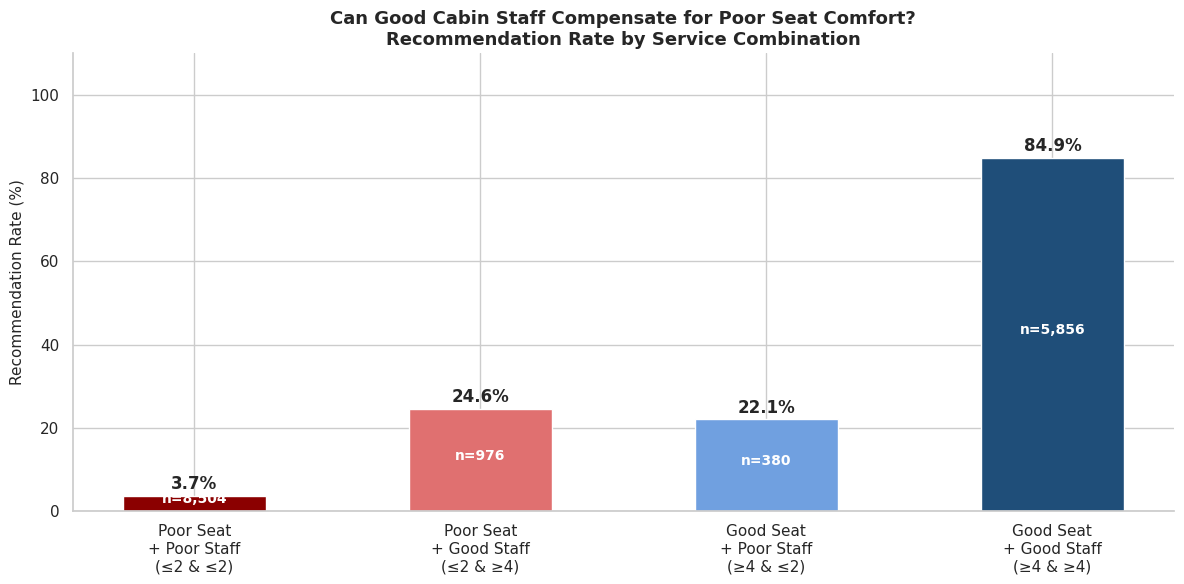

Poor Seat + Poor Staff (≤2 & ≤2): 3.7% (n=8,504)
Poor Seat + Good Staff (≤2 & ≥4): 24.6% (n=976)
Good Seat + Poor Staff (≥4 & ≤2): 22.1% (n=380)
Good Seat + Good Staff (≥4 & ≥4): 84.9% (n=5,856)


In [23]:
# ============================================================
# PART 4a: Visualisation 12 — Cabin Staff Compensation Effect
# ============================================================

groups = {
    'Poor Seat\n+ Poor Staff\n(≤2 & ≤2)': df[
        (df['Seat Comfort'] <= 2) & (df['Cabin Staff Service'] <= 2)]['Recommended'].mean() * 100,
    'Poor Seat\n+ Good Staff\n(≤2 & ≥4)': df[
        (df['Seat Comfort'] <= 2) & (df['Cabin Staff Service'] >= 4)]['Recommended'].mean() * 100,
    'Good Seat\n+ Poor Staff\n(≥4 & ≤2)': df[
        (df['Seat Comfort'] >= 4) & (df['Cabin Staff Service'] <= 2)]['Recommended'].mean() * 100,
    'Good Seat\n+ Good Staff\n(≥4 & ≥4)': df[
        (df['Seat Comfort'] >= 4) & (df['Cabin Staff Service'] >= 4)]['Recommended'].mean() * 100,
}

counts = {
    'Poor Seat\n+ Poor Staff\n(≤2 & ≤2)': len(df[
        (df['Seat Comfort'] <= 2) & (df['Cabin Staff Service'] <= 2)]),
    'Poor Seat\n+ Good Staff\n(≤2 & ≥4)': len(df[
        (df['Seat Comfort'] <= 2) & (df['Cabin Staff Service'] >= 4)]),
    'Good Seat\n+ Poor Staff\n(≥4 & ≤2)': len(df[
        (df['Seat Comfort'] >= 4) & (df['Cabin Staff Service'] <= 2)]),
    'Good Seat\n+ Good Staff\n(≥4 & ≥4)': len(df[
        (df['Seat Comfort'] >= 4) & (df['Cabin Staff Service'] >= 4)]),
}

colors = ['#8B0000', '#E07070', '#70A0E0', '#1F4E79']
labels = list(groups.keys())
values = [round(v, 1) for v in groups.values()]

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(labels, values, color=colors,
              edgecolor='white', width=0.5)

for bar, val, count in zip(bars, values, counts.values()):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 1.5,
            f'{val}%', ha='center',
            fontsize=12, fontweight='bold')
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height()/2,
            f'n={count:,}', ha='center',
            fontsize=10, color='white', fontweight='bold')

ax.set_ylabel('Recommendation Rate (%)', fontsize=11)
ax.set_ylim(0, 110)
ax.set_title('Can Good Cabin Staff Compensate for Poor Seat Comfort?\n'
             'Recommendation Rate by Service Combination',
             fontsize=13, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

for label, val, count in zip(labels, values, counts.values()):
    print(f"{label.replace(chr(10), ' ')}: {val}% (n={count:,})")

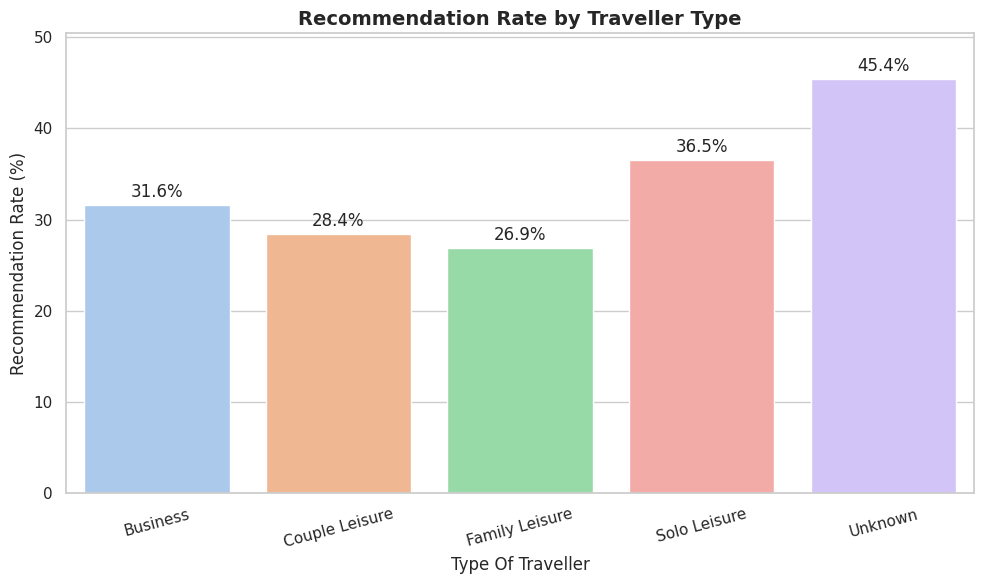

Type Of Traveller  Percentage
         Business        31.6
   Couple Leisure        28.4
   Family Leisure        26.9
     Solo Leisure        36.5
          Unknown        45.4


In [24]:
# ============================================================
# PART 4a: Visualisation 7 — Traveller Type vs Recommendation
# ============================================================

traveller_rec = df.groupby(['Type Of Traveller', 'Recommended']).size().reset_index(name='Count')
traveller_total = df.groupby('Type Of Traveller').size().reset_index(name='Total')
traveller_pct = traveller_rec.merge(traveller_total, on='Type Of Traveller')
traveller_pct['Percentage'] = (traveller_pct['Count'] / traveller_pct['Total'] * 100).round(1)
traveller_pct = traveller_pct[traveller_pct['Recommended'] == 1]

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=traveller_pct,
    x='Type Of Traveller',
    y='Percentage',
    hue='Type Of Traveller',     # avoids palette warning
    palette='pastel',
    dodge=False,
    legend=False
)

# Add percentage labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Recommendation Rate by Traveller Type',
          fontsize=14, fontweight='bold')
plt.xlabel('Type Of Traveller')
plt.ylabel('Recommendation Rate (%)')
plt.xticks(rotation=15)

plt.ylim(0, traveller_pct['Percentage'].max() + 5)

plt.tight_layout()
plt.show()

print(traveller_pct[['Type Of Traveller', 'Percentage']].to_string(index=False))

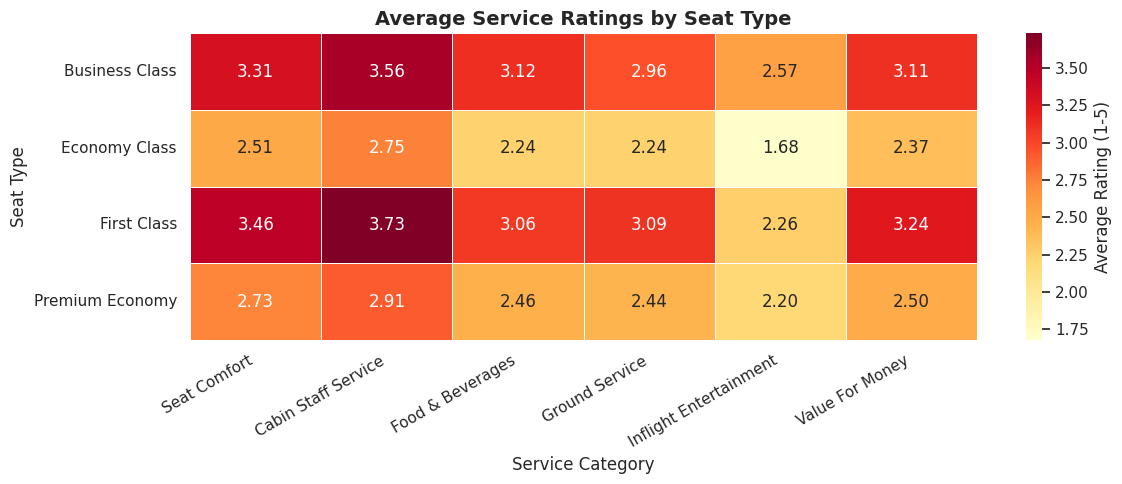

In [25]:
# ============================================================
# PART 4a: Visualisation 8 — Seat Type vs Average Rating Heatmap
# ============================================================

seat_ratings = df.groupby('Seat Type')[numerical_cols].mean().round(2)
seat_ratings = seat_ratings.drop(index='Unknown', errors='ignore')

plt.figure(figsize=(12, 5))
sns.heatmap(seat_ratings, annot=True, fmt='.2f',
            cmap='YlOrRd', linewidths=0.5,
            cbar_kws={'label': 'Average Rating (1-5)'})
plt.title('Average Service Ratings by Seat Type',
          fontsize=14, fontweight='bold')
plt.xlabel('Service Category')
plt.ylabel('Seat Type')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [26]:
# ============================================================
# DIAGNOSTIC: Verify Logical Conflict
# ============================================================

conflict = df[(df['Overall_Rating'] == 1) & (df['Recommended'] == 1)]

print("=" * 50)
print("CONFLICT: Rating=1 but Recommended=Yes")
print("=" * 50)
print(f"Number of rows: {len(conflict)}")
print("\nSample reviews:")
print(conflict[['Airline Name', 'Overall_Rating', 'Recommended', 'Review']].head(5).to_string())

CONFLICT: Rating=1 but Recommended=Yes
Number of rows: 2268

Sample reviews:
     Airline Name  Overall_Rating  Recommended                                                                                                                                                                                                                                                                                                                                                                                                       Review
15  Adria Airways             1.0            1                                                                                                                                                                                                                Frankfurt to Ljubljana. Flight was very comfortable, professional crew. The monitors above passengers provide informations about flight (speed, altitude, temperature, time to landing, etc.)
23  Adria Airways             1.0  

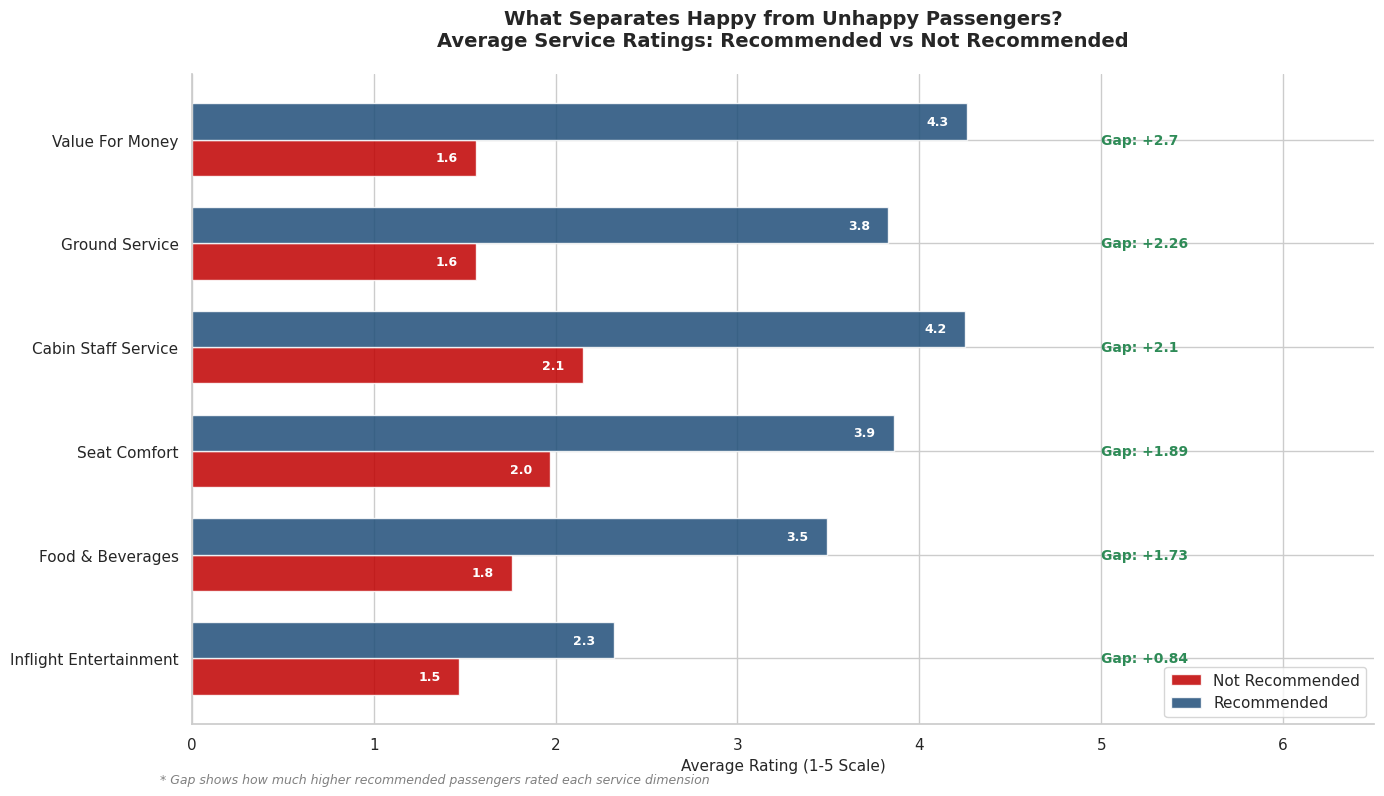


Service Gap Summary (sorted by gap size):
                        Not Recommended  Recommended   Gap
Inflight Entertainment             1.47         2.32  0.84
Food & Beverages                   1.76         3.49  1.73
Seat Comfort                       1.97         3.86  1.89
Cabin Staff Service                2.15         4.25  2.10
Ground Service                     1.56         3.83  2.26
Value For Money                    1.56         4.26  2.70


In [27]:
# ============================================================
# PART 4a: Visualisation 13 — Executive Summary Chart
# (Non-Technical Management Audience)
# ============================================================

# Calculate key metrics
service_gaps = {}
for col in numerical_cols:
    rec_mean = df[df['Recommended'] == 1][col].mean()
    not_rec_mean = df[df['Recommended'] == 0][col].mean()
    service_gaps[col] = {
        'Recommended': round(rec_mean, 2),
        'Not Recommended': round(not_rec_mean, 2),
        'Gap': round(rec_mean - not_rec_mean, 2)
    }

gap_df = pd.DataFrame(service_gaps).T.sort_values('Gap', ascending=True)

fig, ax = plt.subplots(figsize=(14, 8))

y_pos = range(len(gap_df))
bar_height = 0.35

# Not recommended bars
bars1 = ax.barh([y - bar_height/2 for y in y_pos],
                gap_df['Not Recommended'],
                bar_height, color='#C00000',
                label='Not Recommended', alpha=0.85)

# Recommended bars
bars2 = ax.barh([y + bar_height/2 for y in y_pos],
                gap_df['Recommended'],
                bar_height, color='#1F4E79',
                label='Recommended', alpha=0.85)

# Add gap annotations
for i, (idx, row) in enumerate(gap_df.iterrows()):
    ax.annotate(f"Gap: +{row['Gap']}",
                xy=(5, i),
                fontsize=10, va='center',
                color='#2E8B57', fontweight='bold')

# Add value labels on bars
for bar in bars1:
    ax.text(bar.get_width() - 0.1, bar.get_y() + bar.get_height()/2,
            f'{bar.get_width():.1f}', va='center', ha='right',
            color='white', fontsize=9, fontweight='bold')

for bar in bars2:
    ax.text(bar.get_width() - 0.1, bar.get_y() + bar.get_height()/2,
            f'{bar.get_width():.1f}', va='center', ha='right',
            color='white', fontsize=9, fontweight='bold')

ax.set_yticks(list(y_pos))
ax.set_yticklabels(gap_df.index, fontsize=11)
ax.set_xlabel('Average Rating (1-5 Scale)', fontsize=11)
ax.set_xlim(0, 6.5)
ax.set_title('What Separates Happy from Unhappy Passengers?\n'
             'Average Service Ratings: Recommended vs Not Recommended',
             fontsize=14, fontweight='bold', pad=20)
ax.legend(fontsize=11, loc='lower right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Add a footnote
fig.text(0.12, 0.01,
         '* Gap shows how much higher recommended passengers rated each service dimension',
         fontsize=9, color='grey', style='italic')

plt.tight_layout()
plt.show()

print("\nService Gap Summary (sorted by gap size):")
print(gap_df[['Not Recommended', 'Recommended', 'Gap']].to_string())

In [28]:
# ============================================================
# PART 4a: Predictive Modelling — Data Preparation
# ============================================================

from sklearn.preprocessing import RobustScaler

feature_cols = ['Overall_Rating', 'Seat Comfort', 'Cabin Staff Service',
                'Food & Beverages', 'Ground Service',
                'Inflight Entertainment', 'Value For Money']

df_model = df[feature_cols + ['Recommended']].dropna()

print("=" * 50)
print("MODELLING DATASET")
print("=" * 50)
print(f"Shape after dropping NaN: {df_model.shape}")
print(f"\nClass distribution:")
print(df_model['Recommended'].value_counts())

X = df_model[feature_cols]
y = df_model['Recommended']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=40481810, stratify=y
)

print(f"\nTraining set: {X_train.shape}")
print(f"Test set: {X_test.shape}")

scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nScaling complete.")

MODELLING DATASET
Shape after dropping NaN: (22329, 8)

Class distribution:
Recommended
0    14527
1     7802
Name: count, dtype: int64

Training set: (15630, 7)
Test set: (6699, 7)

Scaling complete.


In [29]:
# ============================================================
# PART 4a: Cell 1 — Train Both Models
# ============================================================

from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.metrics import precision_score, recall_score, f1_score

# --- Random Forest ---
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    class_weight='balanced',
    random_state=40481810
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("=" * 50)
print("RANDOM FOREST — DEFAULT THRESHOLD (0.5)")
print("=" * 50)
print(classification_report(y_test, rf_pred))
print(f"ROC-AUC: {roc_auc_score(y_test, rf_prob):.4f}")
print(f"PR-AUC:  {average_precision_score(y_test, rf_prob):.4f}")

# --- Logistic Regression ---
lr_model = LogisticRegression(
    C=1.0,
    class_weight='balanced',
    max_iter=1000,
    random_state=40481810
)
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

print("\n" + "=" * 50)
print("LOGISTIC REGRESSION — DEFAULT THRESHOLD (0.5)")
print("=" * 50)
print(classification_report(y_test, lr_pred))
print(f"ROC-AUC: {roc_auc_score(y_test, lr_prob):.4f}")
print(f"PR-AUC:  {average_precision_score(y_test, lr_prob):.4f}")

RANDOM FOREST — DEFAULT THRESHOLD (0.5)
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      4358
           1       0.94      0.94      0.94      2341

    accuracy                           0.96      6699
   macro avg       0.95      0.95      0.95      6699
weighted avg       0.96      0.96      0.96      6699

ROC-AUC: 0.9851
PR-AUC:  0.9738

LOGISTIC REGRESSION — DEFAULT THRESHOLD (0.5)
              precision    recall  f1-score   support

           0       0.97      0.92      0.95      4358
           1       0.87      0.95      0.91      2341

    accuracy                           0.93      6699
   macro avg       0.92      0.94      0.93      6699
weighted avg       0.94      0.93      0.93      6699

ROC-AUC: 0.9776
PR-AUC:  0.9587


In [30]:
# ============================================================
# PART 4a: Cell 2 — Threshold Analysis
# ============================================================

print("=" * 50)
print("RF THRESHOLD ANALYSIS")
print("=" * 50)
print(f"{'Threshold':<12} {'Precision':<12} {'Recall':<12} {'F1':<12}")
best_rf_thresh, best_rf_f1 = 0.5, 0
for thresh in [0.3, 0.4, 0.5, 0.6, 0.7]:
    preds = (rf_prob >= thresh).astype(int)
    p = precision_score(y_test, preds, zero_division=0)
    r = recall_score(y_test, preds, zero_division=0)
    f = f1_score(y_test, preds, zero_division=0)
    marker = " <-- best F1" if f > best_rf_f1 else ""
    if f > best_rf_f1:
        best_rf_f1 = f
        best_rf_thresh = thresh
    print(f"{thresh:<12.1f} {p:<12.4f} {r:<12.4f} {f:<12.4f}{marker}")

print(f"\nBest RF threshold: {best_rf_thresh} (F1 = {best_rf_f1:.4f})")
rf_pred_best = (rf_prob >= best_rf_thresh).astype(int)
print("\nRF AT BEST THRESHOLD:")
print(classification_report(y_test, rf_pred_best))

print("\n" + "=" * 50)
print("LR THRESHOLD ANALYSIS")
print("=" * 50)
print(f"{'Threshold':<12} {'Precision':<12} {'Recall':<12} {'F1':<12}")
best_lr_thresh, best_lr_f1 = 0.5, 0
for thresh in [0.3, 0.4, 0.5, 0.6, 0.7]:
    preds = (lr_prob >= thresh).astype(int)
    p = precision_score(y_test, preds, zero_division=0)
    r = recall_score(y_test, preds, zero_division=0)
    f = f1_score(y_test, preds, zero_division=0)
    marker = " <-- best F1" if f > best_lr_f1 else ""
    if f > best_lr_f1:
        best_lr_f1 = f
        best_lr_thresh = thresh
    print(f"{thresh:<12.1f} {p:<12.4f} {r:<12.4f} {f:<12.4f}{marker}")

print(f"\nBest LR threshold: {best_lr_thresh} (F1 = {best_lr_f1:.4f})")
lr_pred_best = (lr_prob >= best_lr_thresh).astype(int)
print("\nLR AT BEST THRESHOLD:")
print(classification_report(y_test, lr_pred_best))

RF THRESHOLD ANALYSIS
Threshold    Precision    Recall       F1          
0.3          0.9033       0.9573       0.9295       <-- best F1
0.4          0.9237       0.9470       0.9352       <-- best F1
0.5          0.9359       0.9359       0.9359       <-- best F1
0.6          0.9512       0.9244       0.9376       <-- best F1
0.7          0.9602       0.9077       0.9332      

Best RF threshold: 0.6 (F1 = 0.9376)

RF AT BEST THRESHOLD:
              precision    recall  f1-score   support

           0       0.96      0.97      0.97      4358
           1       0.95      0.92      0.94      2341

    accuracy                           0.96      6699
   macro avg       0.96      0.95      0.95      6699
weighted avg       0.96      0.96      0.96      6699


LR THRESHOLD ANALYSIS
Threshold    Precision    Recall       F1          
0.3          0.8189       0.9658       0.8863       <-- best F1
0.4          0.8472       0.9590       0.8996       <-- best F1
0.5          0.8711       0

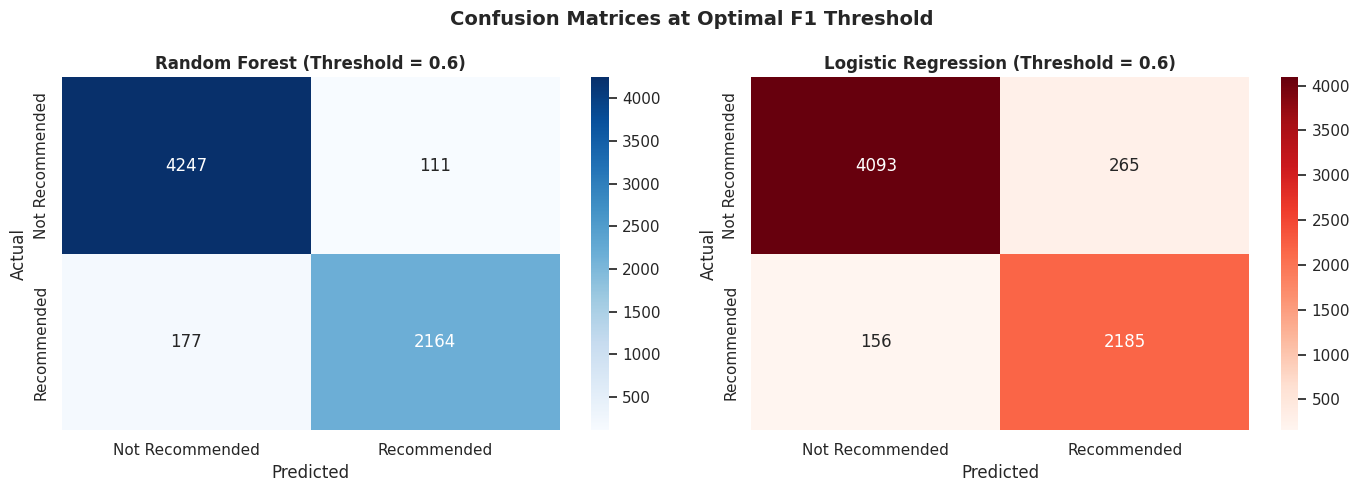

In [31]:
# ============================================================
# PART 4a: Cell 3 — Confusion Matrices at Best Threshold
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# RF Confusion Matrix
sns.heatmap(confusion_matrix(y_test, rf_pred_best),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Recommended', 'Recommended'],
            yticklabels=['Not Recommended', 'Recommended'],
            ax=axes[0])
axes[0].set_title(f'Random Forest (Threshold = {best_rf_thresh})',
                  fontweight='bold')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# LR Confusion Matrix
sns.heatmap(confusion_matrix(y_test, lr_pred_best),
            annot=True, fmt='d', cmap='Reds',
            xticklabels=['Not Recommended', 'Recommended'],
            yticklabels=['Not Recommended', 'Recommended'],
            ax=axes[1])
axes[1].set_title(f'Logistic Regression (Threshold = {best_lr_thresh})',
                  fontweight='bold')
axes[1].set_ylabel('Actual')
axes[1].set_xlabel('Predicted')

plt.suptitle('Confusion Matrices at Optimal F1 Threshold',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

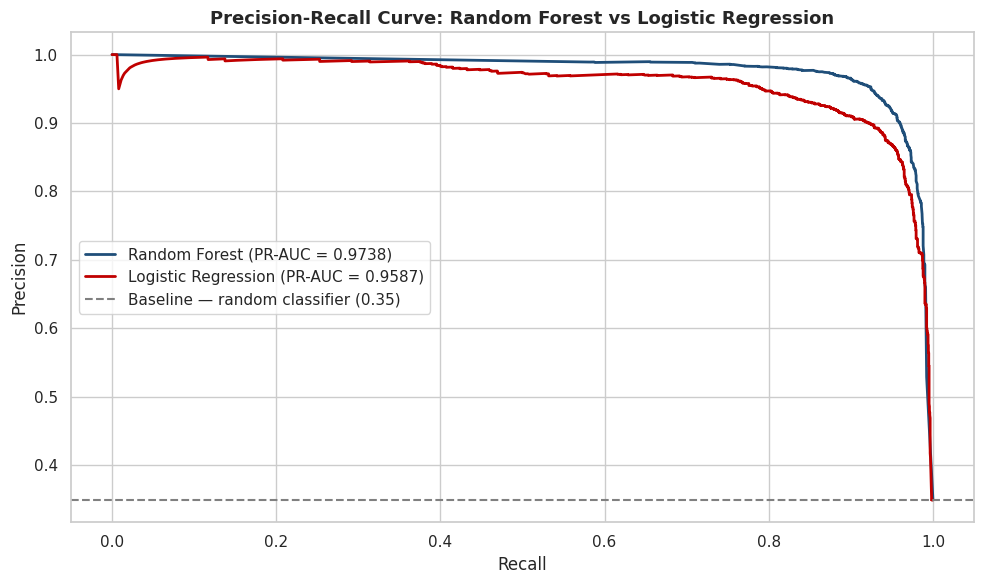

Random Forest   PR-AUC: 0.9738
Logistic Reg    PR-AUC: 0.9587
Baseline:               0.3495


In [32]:
# ============================================================
# PART 4a: Cell 4 — Precision Recall Curve
# ============================================================

rf_precision, rf_recall, _ = precision_recall_curve(y_test, rf_prob)
lr_precision, lr_recall, _ = precision_recall_curve(y_test, lr_prob)

rf_auc = average_precision_score(y_test, rf_prob)
lr_auc = average_precision_score(y_test, lr_prob)

baseline = y_test.sum() / len(y_test)

plt.figure(figsize=(10, 6))
plt.plot(rf_recall, rf_precision, color='#1F4E79', linewidth=2,
         label=f'Random Forest (PR-AUC = {rf_auc:.4f})')
plt.plot(lr_recall, lr_precision, color='#C00000', linewidth=2,
         label=f'Logistic Regression (PR-AUC = {lr_auc:.4f})')
plt.axhline(y=baseline, color='grey', linestyle='--', linewidth=1.5,
            label=f'Baseline — random classifier ({baseline:.2f})')
plt.title('Precision-Recall Curve: Random Forest vs Logistic Regression',
          fontsize=13, fontweight='bold')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

print(f"Random Forest   PR-AUC: {rf_auc:.4f}")
print(f"Logistic Reg    PR-AUC: {lr_auc:.4f}")
print(f"Baseline:               {baseline:.4f}")

In [33]:
# ============================================================
# PART 4a: Cell 5 — Hyperparameter Tuning
# ============================================================

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# --- Random Forest Tuning ---
rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(
        class_weight='balanced',
        random_state=40481810
    ),
    param_grid=rf_param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
rf_grid.fit(X_train, y_train)

print("=" * 50)
print("RANDOM FOREST — BEST HYPERPARAMETERS")
print("=" * 50)
print(f"Best params: {rf_grid.best_params_}")
print(f"Best CV F1:  {rf_grid.best_score_:.4f}")

rf_best = rf_grid.best_estimator_
rf_best_pred = (rf_best.predict_proba(X_test)[:, 1] >= best_rf_thresh).astype(int)
print("\nRF TUNED MODEL RESULTS:")
print(classification_report(y_test, rf_best_pred))

# --- Logistic Regression Tuning ---
lr_param_grid = {
    'C': [0.1, 1.0, 10.0],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

lr_grid = GridSearchCV(
    LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=40481810
    ),
    param_grid=lr_param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
lr_grid.fit(X_train_scaled, y_train)

print("\n" + "=" * 50)
print("LOGISTIC REGRESSION — BEST HYPERPARAMETERS")
print("=" * 50)
print(f"Best params: {lr_grid.best_params_}")
print(f"Best CV F1:  {lr_grid.best_score_:.4f}")

lr_best = lr_grid.best_estimator_
lr_best_pred = (lr_best.predict_proba(X_test_scaled)[:, 1] >= best_lr_thresh).astype(int)
print("\nLR TUNED MODEL RESULTS:")
print(classification_report(y_test, lr_best_pred))

Fitting 5 folds for each of 9 candidates, totalling 45 fits
RANDOM FOREST — BEST HYPERPARAMETERS
Best params: {'max_depth': 10, 'n_estimators': 100}
Best CV F1:  0.9485

RF TUNED MODEL RESULTS:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      4358
           1       0.95      0.94      0.94      2341

    accuracy                           0.96      6699
   macro avg       0.96      0.96      0.96      6699
weighted avg       0.96      0.96      0.96      6699

Fitting 5 folds for each of 6 candidates, totalling 30 fits

LOGISTIC REGRESSION — BEST HYPERPARAMETERS
Best params: {'C': 1.0, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV F1:  0.9154

LR TUNED MODEL RESULTS:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95      4358
           1       0.89      0.93      0.91      2341

    accuracy                           0.94      6699
   macro avg       0.93      0.94      0.93     

In [34]:
# ============================================================
# PART 4a: Cell 6 — Robustness / Stress Test
# Train on subset of airlines, test on others
# ============================================================

# --- Recreate df_model with Airline Name included ---
df_model_robust = df[feature_cols + ['Recommended', 'Airline Name']].dropna()

# --- Split airlines into two groups ---
airlines = df_model_robust['Airline Name'].unique()
np.random.seed(40481810)
np.random.shuffle(airlines)

split = len(airlines) // 2
train_airlines = airlines[:split]
test_airlines = airlines[split:]

print("=" * 50)
print("ROBUSTNESS TEST — AIRLINE SPLIT")
print("=" * 50)
print(f"Total airlines: {len(airlines)}")
print(f"Training airlines: {len(train_airlines)}")
print(f"Testing airlines: {len(test_airlines)}")

# --- Create robustness train/test sets ---
robust_train = df_model_robust[df_model_robust['Airline Name'].isin(train_airlines)]
robust_test = df_model_robust[df_model_robust['Airline Name'].isin(test_airlines)]

X_robust_train = robust_train[feature_cols]
y_robust_train = robust_train['Recommended']
X_robust_test = robust_test[feature_cols]
y_robust_test = robust_test['Recommended']

print(f"\nRobust train size: {X_robust_train.shape}")
print(f"Robust test size:  {X_robust_test.shape}")
print(f"\nClass distribution in robust test set:")
print(y_robust_test.value_counts())

# --- Scale for LR ---
X_robust_train_scaled = scaler.fit_transform(X_robust_train)
X_robust_test_scaled = scaler.transform(X_robust_test)

# --- RF Robustness ---
rf_robust = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=40481810
)
rf_robust.fit(X_robust_train, y_robust_train)
rf_robust_prob = rf_robust.predict_proba(X_robust_test)[:, 1]
rf_robust_pred = (rf_robust_prob >= best_rf_thresh).astype(int)

print("\n" + "=" * 50)
print("RF ROBUSTNESS TEST RESULTS")
print("=" * 50)
print(classification_report(y_robust_test, rf_robust_pred))
print(f"PR-AUC: {average_precision_score(y_robust_test, rf_robust_prob):.4f}")

# --- LR Robustness ---
lr_robust = LogisticRegression(
    C=1.0,
    penalty='l2',
    solver='liblinear',
    class_weight='balanced',
    max_iter=1000,
    random_state=40481810
)
lr_robust.fit(X_robust_train_scaled, y_robust_train)
lr_robust_prob = lr_robust.predict_proba(X_robust_test_scaled)[:, 1]
lr_robust_pred = (lr_robust_prob >= best_lr_thresh).astype(int)

print("\n" + "=" * 50)
print("LR ROBUSTNESS TEST RESULTS")
print("=" * 50)
print(classification_report(y_robust_test, lr_robust_pred))
print(f"PR-AUC: {average_precision_score(y_robust_test, lr_robust_prob):.4f}")

# --- Comparison ---
print("\n" + "=" * 50)
print("COMPARISON: NORMAL vs ROBUSTNESS TEST")
print("=" * 50)
print(f"{'Model':<25} {'Normal PR-AUC':<18} {'Robust PR-AUC':<18} {'Drop'}")
print(f"{'Random Forest':<25} {average_precision_score(y_test, rf_prob):<18.4f} {average_precision_score(y_robust_test, rf_robust_prob):<18.4f} {average_precision_score(y_test, rf_prob) - average_precision_score(y_robust_test, rf_robust_prob):.4f}")
print(f"{'Logistic Regression':<25} {average_precision_score(y_test, lr_prob):<18.4f} {average_precision_score(y_robust_test, lr_robust_prob):<18.4f} {average_precision_score(y_test, lr_prob) - average_precision_score(y_robust_test, lr_robust_prob):.4f}")

ROBUSTNESS TEST — AIRLINE SPLIT
Total airlines: 497
Training airlines: 248
Testing airlines: 249

Robust train size: (11333, 7)
Robust test size:  (10996, 7)

Class distribution in robust test set:
Recommended
0    6946
1    4050
Name: count, dtype: int64

RF ROBUSTNESS TEST RESULTS
              precision    recall  f1-score   support

           0       0.96      0.97      0.97      6946
           1       0.95      0.94      0.95      4050

    accuracy                           0.96     10996
   macro avg       0.96      0.96      0.96     10996
weighted avg       0.96      0.96      0.96     10996

PR-AUC: 0.9830

LR ROBUSTNESS TEST RESULTS
              precision    recall  f1-score   support

           0       0.97      0.94      0.95      6946
           1       0.90      0.95      0.92      4050

    accuracy                           0.94     10996
   macro avg       0.93      0.94      0.94     10996
weighted avg       0.94      0.94      0.94     10996

PR-AUC: 0.9659

COM

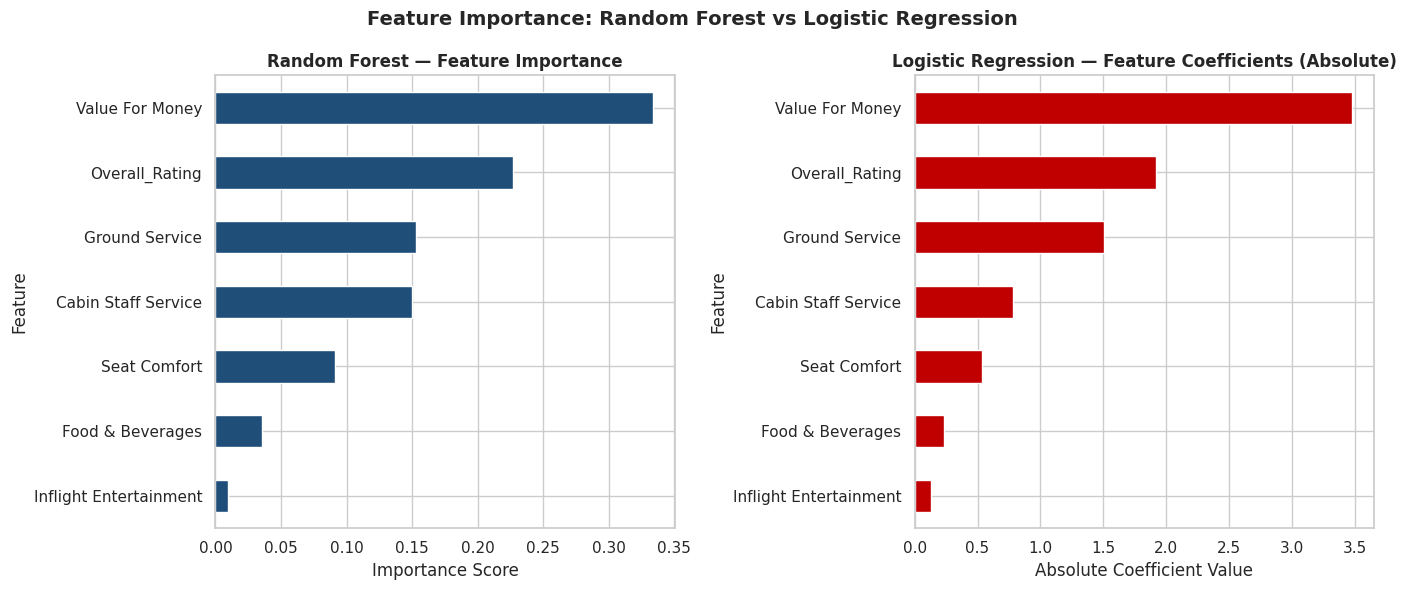

RF FEATURE IMPORTANCE (ranked)
Value For Money           0.3336
Overall_Rating            0.2272
Ground Service            0.1532
Cabin Staff Service       0.1501
Seat Comfort              0.0910
Food & Beverages          0.0354
Inflight Entertainment    0.0096
dtype: float64

LR FEATURE COEFFICIENTS (absolute, ranked)
Value For Money           3.4771
Overall_Rating            1.9167
Ground Service            1.5045
Cabin Staff Service       0.7786
Seat Comfort              0.5330
Food & Beverages          0.2312
Inflight Entertainment    0.1289
dtype: float64


In [35]:
# ============================================================
# PART 4a: Cell 7 — Feature Importance Plot
# ============================================================

# --- Random Forest Feature Importance ---
importances = pd.Series(
    rf_best.feature_importances_,
    index=feature_cols
).sort_values(ascending=True)

# --- Logistic Regression Coefficients ---
lr_coefficients = pd.Series(
    np.abs(lr_best.coef_[0]),
    index=feature_cols
).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# RF importance
importances.plot(kind='barh', ax=axes[0], color='#1F4E79', edgecolor='white')
axes[0].set_title('Random Forest — Feature Importance',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Importance Score')
axes[0].set_ylabel('Feature')

# LR coefficients
lr_coefficients.plot(kind='barh', ax=axes[1], color='#C00000', edgecolor='white')
axes[1].set_title('Logistic Regression — Feature Coefficients (Absolute)',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Absolute Coefficient Value')
axes[1].set_ylabel('Feature')

plt.suptitle('Feature Importance: Random Forest vs Logistic Regression',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("=" * 50)
print("RF FEATURE IMPORTANCE (ranked)")
print("=" * 50)
print(importances.sort_values(ascending=False).round(4))

print("\n" + "=" * 50)
print("LR FEATURE COEFFICIENTS (absolute, ranked)")
print("=" * 50)
print(lr_coefficients.sort_values(ascending=False).round(4))

In [36]:
# ============================================================
# PART 3b: Cell 2 — Define and Apply Pipeline
# ============================================================

def clean_text(text):
    if pd.isnull(text):
        return ''
    # Expand contractions
    try:
        text = contractions.fix(text)
    except:
        pass
    # Negation handling
    negation_words = ['not', 'never', 'no', 'cannot',
                      'neither', 'nor', 'hardly', 'barely', 'scarcely']
    tokens = text.split()
    result = []
    i = 0
    while i < len(tokens):
        if tokens[i].lower() in negation_words and i + 1 < len(tokens):
            result.append(tokens[i] + '_' + tokens[i+1])
            i += 2
        else:
            result.append(tokens[i])
            i += 1
    text = ' '.join(result)
    # Clean
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'<[^>]+>', '', text)
    text = text.lower()
    text = re.sub(r'\b\w{1,2}\b', '', text)
    text = re.sub(r'[^a-z\s_]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    # Tokenise
    tokenizer = TreebankWordTokenizer()
    tokens = tokenizer.tokenize(text)
    # Stopwords — preserve negation
    stop_words = set(stopwords.words('english'))
    stop_words -= {'not', 'no', 'never', 'nor', 'neither',
                   'hardly', 'barely', 'scarcely'}
    tokens = [w for w in tokens if w not in stop_words]
    # Lemmatise
    lemmatizer = WordNetLemmatizer()
    tokens = [lemmatizer.lemmatize(w) for w in tokens]
    return ' '.join(tokens)

print("Applying pipeline...")
df['Review_Cleaned'] = df['Review'].apply(clean_text)
print(f"Done! Processed {df['Review_Cleaned'].notna().sum()} reviews.")

Applying pipeline...
Done! Processed 23171 reviews.


In [37]:
# ============================================================
# PART 3b: Cell 3 — Before vs After Examples
# ============================================================

print("=" * 50)
print("BEFORE vs AFTER — 3 EXAMPLES")
print("=" * 50)
for idx in df['Review'].dropna().head(3).index:
    print(f"\nORIGINAL:\n{str(df.loc[idx, 'Review'])[:200]}")
    print(f"\nCLEANED:\n{df.loc[idx, 'Review_Cleaned'][:200]}")
    print("-" * 50)

BEFORE vs AFTER — 3 EXAMPLES

ORIGINAL:
  Moroni to Moheli. Turned out to be a pretty decent airline. Online booking worked well, checkin and boarding was fine and the plane looked well maintained. Its a very short flight - just 20 minutes 

CLEANED:
moroni moheli turned pretty decent airline online booking worked well checkin boarding fine plane looked well maintained short flight minute not_expect much still managed hand bottle water biscuit tho
--------------------------------------------------

ORIGINAL:
 Moroni to Anjouan. It is a very small airline. My ticket advised me to turn up at 0800hrs which I did. There was confusion at this small airport. I was then directed to the office of AB Aviation whic

CLEANED:
moroni anjouan small airline ticket advised turn hr confusion small airport directed office aviation still closed opened hr told flight put back hr tried contact could not_be true not_have phone numbe
--------------------------------------------------

ORIGINAL:
  Anjouan to

In [38]:
# ============================================================
# PART 3b: Cell 4 — Dataset Specific Linguistic Findings
# ============================================================

all_words = ' '.join(df['Review_Cleaned'].dropna()).split()

print("=" * 50)
print("TOP 15 NEGATION PHRASES")
print("=" * 50)
print(Counter(negation_phrases := [w for w in all_words if '_' in w]).most_common(15))

print("\n" + "=" * 50)
print("TOP WORDS — NOT RECOMMENDED")
print("=" * 50)
print(Counter(' '.join(df[df['Recommended']==0]['Review_Cleaned'].dropna()).split()).most_common(15))

print("\n" + "=" * 50)
print("TOP WORDS — RECOMMENDED")
print("=" * 50)
print(Counter(' '.join(df[df['Recommended']==1]['Review_Cleaned'].dropna()).split()).most_common(15))

TOP 15 NEGATION PHRASES
[('not_have', 1848), ('not_even', 1528), ('no_one', 1221), ('not_be', 1020), ('not_a', 913), ('never_fly', 887), ('not_get', 759), ('not_know', 708), ('not_the', 695), ('not_recommend', 659), ('not_fly', 630), ('not_work', 596), ('not_to', 572), ('not_care', 567), ('not_want', 431)]

TOP WORDS — NOT RECOMMENDED
[('flight', 35581), ('airline', 14265), ('hour', 10852), ('time', 10010), ('service', 8849), ('seat', 8069), ('would', 7937), ('airport', 6809), ('customer', 6188), ('day', 6001), ('plane', 5777), ('get', 5653), ('ticket', 5651), ('one', 5524), ('check', 5404)]

TOP WORDS — RECOMMENDED
[('flight', 14888), ('seat', 5295), ('time', 5170), ('good', 4701), ('airline', 4683), ('service', 4623), ('crew', 3937), ('cabin', 3050), ('food', 3017), ('staff', 2998), ('check', 2761), ('would', 2453), ('plane', 2440), ('friendly', 2257), ('hour', 2218)]


In [39]:
# ============================================================
# PART 4b: Cell 1 — TextBlob Sentiment Analysis (Full Dataset)
# ============================================================

!pip install textblob -q

from textblob import TextBlob

def analyze_sentiment(text):

    if pd.isnull(text) or text == '':
        return 'Neutral', 0.0
    blob = TextBlob(text)
    polarity = blob.sentiment.polarity
    if polarity > 0:
        sentiment = 'Positive'
    elif polarity < 0:
        sentiment = 'Negative'
    else:
        sentiment = 'Neutral'
    return sentiment, polarity

print("Applying TextBlob sentiment analysis...")
df[['TB_Sentiment', 'TB_Polarity']] = df['Review'].apply(
    lambda x: pd.Series(analyze_sentiment(x))
)
print("Done!")

print("\n" + "=" * 50)
print("TEXTBLOB SENTIMENT DISTRIBUTION")
print("=" * 50)
print(df['TB_Sentiment'].value_counts())

print("\n" + "=" * 50)
print("TEXTBLOB POLARITY STATS")
print("=" * 50)
print(df['TB_Polarity'].describe().round(3))

print("\n" + "=" * 50)
print("TEXTBLOB SENTIMENT vs RECOMMENDED")
print("=" * 50)
print(pd.crosstab(df['TB_Sentiment'], df['Recommended'],
                  normalize='index').round(3) * 100)

Applying TextBlob sentiment analysis...
Done!

TEXTBLOB SENTIMENT DISTRIBUTION
TB_Sentiment
Positive    14375
Negative     8517
Neutral       279
Name: count, dtype: int64

TEXTBLOB POLARITY STATS
count    23171.000
mean         0.068
std          0.226
min         -1.000
25%         -0.063
50%          0.059
75%          0.207
max          1.000
Name: TB_Polarity, dtype: float64

TEXTBLOB SENTIMENT vs RECOMMENDED
Recommended      0     1
TB_Sentiment            
Negative      95.5   4.5
Neutral       92.8   7.2
Positive      48.5  51.5


In [40]:
# ============================================================
# PART 4b: Cell 2 — HuggingFace Emotion Analysis (5,000 sample)
#Used AI to debug
# ============================================================

from transformers import pipeline
import torch

# --- Step 1: Create stratified sample ---
# We sample proportionally to maintain the 2:1 class ratio
# 3333 not recommended + 1667 recommended = 5000 total
sample_rec = df[df['Recommended'] == 1].sample(n=667, random_state=40481810)
sample_not_rec = df[df['Recommended'] == 0].sample(n=1333, random_state=40481810)
df_sample = pd.concat([sample_rec, sample_not_rec]).reset_index(drop=True)

print(f"Sample size: {len(df_sample)}")
print(f"Class distribution:\n{df_sample['Recommended'].value_counts()}")

# --- Step 2: Load the emotion model ---

# torch.cuda.is_available() automatically detects if GPU is available
device = 0 if torch.cuda.is_available() else -1
print(f"\nUsing: {'GPU' if device == 0 else 'CPU'}")

emotion_model = pipeline(
    "text-classification",
    model="j-hartmann/emotion-english-distilroberta-base",
    device=device
)
print("Model loaded!")

# --- Step 3: Define emotion function ---
# truncation cuts reviews longer than 512 words the model can handle
def analyze_emotion(text):
    if pd.isnull(text) or text == '':
        return 'neutral', 0.0
    result = emotion_model(str(text)[:512], truncation=True)[0]
    return result['label'], result['score']

# --- Step 4: Apply to sample ---
print("\nApplying emotion analysis...")
df_sample[['Emotion', 'Emotion_Score']] = df_sample['Review'].apply(
    lambda x: pd.Series(analyze_emotion(x))
)
print("Done!")

# --- Step 5: Results ---
print("\n" + "=" * 50)
print("EMOTION DISTRIBUTION")
print("=" * 50)
print(df_sample['Emotion'].value_counts())

print("\n" + "=" * 50)
print("EMOTION vs RECOMMENDED")
print("=" * 50)
print(pd.crosstab(df_sample['Emotion'], df_sample['Recommended'],
                  normalize='index').round(3) * 100)

Sample size: 2000
Class distribution:
Recommended
0    1333
1     667
Name: count, dtype: int64

Using: GPU


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/329M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-distilroberta-base
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Model loaded!

Applying emotion analysis...


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Done!

EMOTION DISTRIBUTION
Emotion
neutral     469
sadness     430
joy         288
disgust     229
fear        213
surprise    200
anger       171
Name: count, dtype: int64

EMOTION vs RECOMMENDED
Recommended     0     1
Emotion                
anger        94.7   5.3
disgust      93.4   6.6
fear         84.5  15.5
joy           8.3  91.7
neutral      50.3  49.7
sadness      93.3   6.7
surprise     58.0  42.0


In [41]:
# ============================================================
# PART 4b: Cell 3 — Compare TextBlob vs HuggingFace
# ============================================================

# --- Step 1: Add TextBlob results to sample directly ---
# Instead of merging, apply TextBlob directly to the sample
df_sample[['TB_Sentiment', 'TB_Polarity']] = df_sample['Review'].apply(
    lambda x: pd.Series(analyze_sentiment(x))
)

print("=" * 50)
print("APPROACH COMPARISON")
print("=" * 50)

# --- Step 2: TextBlob alignment with Recommended ---
tb_positive_rec = len(df_sample[
    (df_sample['TB_Sentiment'] == 'Positive') &
    (df_sample['Recommended'] == 1)]) / len(df_sample[df_sample['Recommended'] == 1]) * 100

tb_negative_not = len(df_sample[
    (df_sample['TB_Sentiment'] == 'Negative') &
    (df_sample['Recommended'] == 0)]) / len(df_sample[df_sample['Recommended'] == 0]) * 100

# --- Step 3: HuggingFace alignment with Recommended ---
hf_joy_rec = len(df_sample[
    (df_sample['Emotion'] == 'joy') &
    (df_sample['Recommended'] == 1)]) / len(df_sample[df_sample['Recommended'] == 1]) * 100

hf_neg_not = len(df_sample[
    (df_sample['Emotion'].isin(['anger', 'disgust', 'sadness'])) &
    (df_sample['Recommended'] == 0)]) / len(df_sample[df_sample['Recommended'] == 0]) * 100

print(f"\nTextBlob:")
print(f"  Positive sentiment in recommended reviews:     {tb_positive_rec:.1f}%")
print(f"  Negative sentiment in not recommended reviews: {tb_negative_not:.1f}%")

print(f"\nHuggingFace:")
print(f"  Joy emotion in recommended reviews:            {hf_joy_rec:.1f}%")
print(f"  Negative emotions in not recommended reviews:  {hf_neg_not:.1f}%")

# --- Step 4: Contradiction cases ---
print("\n" + "=" * 50)
print("CONTRADICTION CASES")
print("=" * 50)

pos_not_rec = df_sample[
    (df_sample['TB_Sentiment'] == 'Positive') &
    (df_sample['Recommended'] == 0)]
print(f"TextBlob Positive but NOT Recommended: {len(pos_not_rec)}")

neg_rec = df_sample[
    (df_sample['TB_Sentiment'] == 'Negative') &
    (df_sample['Recommended'] == 1)]
print(f"TextBlob Negative but Recommended: {len(neg_rec)}")

joy_not_rec = df_sample[
    (df_sample['Emotion'] == 'joy') &
    (df_sample['Recommended'] == 0)]
print(f"HuggingFace Joy but NOT Recommended: {len(joy_not_rec)}")

anger_rec = df_sample[
    (df_sample['Emotion'].isin(['anger', 'disgust'])) &
    (df_sample['Recommended'] == 1)]
print(f"HuggingFace Anger/Disgust but Recommended: {len(anger_rec)}")

APPROACH COMPARISON

TextBlob:
  Positive sentiment in recommended reviews:     94.2%
  Negative sentiment in not recommended reviews: 52.4%

HuggingFace:
  Joy emotion in recommended reviews:            39.6%
  Negative emotions in not recommended reviews:  58.3%

CONTRADICTION CASES
TextBlob Positive but NOT Recommended: 616
TextBlob Negative but Recommended: 39
HuggingFace Joy but NOT Recommended: 24
HuggingFace Anger/Disgust but Recommended: 24


In [42]:
# ============================================================
# PART 4b: Cell 4 — 10 Ambiguous/Misclassified Reviews Analysis( Generated using AI)
# ============================================================

print("=" * 50)
print("AMBIGUOUS CASE 1-5: TextBlob POSITIVE but NOT Recommended")
print("=" * 50)
ambiguous_tb = df_sample[
    (df_sample['TB_Sentiment'] == 'Positive') &
    (df_sample['Recommended'] == 0)
][['Review', 'TB_Sentiment', 'TB_Polarity', 'Emotion', 'Recommended']].head(5)

for i, (_, row) in enumerate(ambiguous_tb.iterrows(), 1):
    print(f"\nCase {i}:")
    print(f"Review: {str(row['Review'])[:300]}")
    print(f"TextBlob: {row['TB_Sentiment']} (polarity={row['TB_Polarity']:.3f})")
    print(f"HuggingFace Emotion: {row['Emotion']}")
    print(f"Recommended: {row['Recommended']}")
    print("-" * 50)

print("\n" + "=" * 50)
print("AMBIGUOUS CASE 6-8: HuggingFace JOY but NOT Recommended")
print("=" * 50)
ambiguous_hf = df_sample[
    (df_sample['Emotion'] == 'joy') &
    (df_sample['Recommended'] == 0)
][['Review', 'TB_Sentiment', 'TB_Polarity', 'Emotion', 'Recommended']].head(3)

for i, (_, row) in enumerate(ambiguous_hf.iterrows(), 6):
    print(f"\nCase {i}:")
    print(f"Review: {str(row['Review'])[:300]}")
    print(f"TextBlob: {row['TB_Sentiment']} (polarity={row['TB_Polarity']:.3f})")
    print(f"HuggingFace Emotion: {row['Emotion']}")
    print(f"Recommended: {row['Recommended']}")
    print("-" * 50)

print("\n" + "=" * 50)
print("AMBIGUOUS CASE 9-10: TextBlob NEGATIVE but Recommended")
print("=" * 50)
ambiguous_neg = df_sample[
    (df_sample['TB_Sentiment'] == 'Negative') &
    (df_sample['Recommended'] == 1)
][['Review', 'TB_Sentiment', 'TB_Polarity', 'Emotion', 'Recommended']].head(2)

for i, (_, row) in enumerate(ambiguous_neg.iterrows(), 9):
    print(f"\nCase {i}:")
    print(f"Review: {str(row['Review'])[:300]}")
    print(f"TextBlob: {row['TB_Sentiment']} (polarity={row['TB_Polarity']:.3f})")
    print(f"HuggingFace Emotion: {row['Emotion']}")
    print(f"Recommended: {row['Recommended']}")
    print("-" * 50)

AMBIGUOUS CASE 1-5: TextBlob POSITIVE but NOT Recommended

Case 1:
Review:   My husband and I flew return to Tenerife with Thomas Cook Airlines. We booked and paid for meals on both the outbound and inward flights. When we expected to get these meals the staff had no record of it so were left without. The cabin crew manager on the return flight was very haughty and made us
TextBlob: Positive (polarity=0.092)
HuggingFace Emotion: anger
Recommended: 0
--------------------------------------------------

Case 2:
Review:   5pm flight was cancelled at 9:45pm. A JetBlue representative online said we would get hotel vouchers as the next available flight was 48 hours later. When we asked for compensation for our hotel, JetBlue stated it wasn’t their responsibility since the delay was weather related. Very unprofessional
TextBlob: Positive (polarity=0.000)
HuggingFace Emotion: sadness
Recommended: 0
--------------------------------------------------

Case 3:
Review:   Terrible airline. On the fi

/tmp/ipykernel_7919/504858337.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{abs(int(t))}%' for t in ticks])


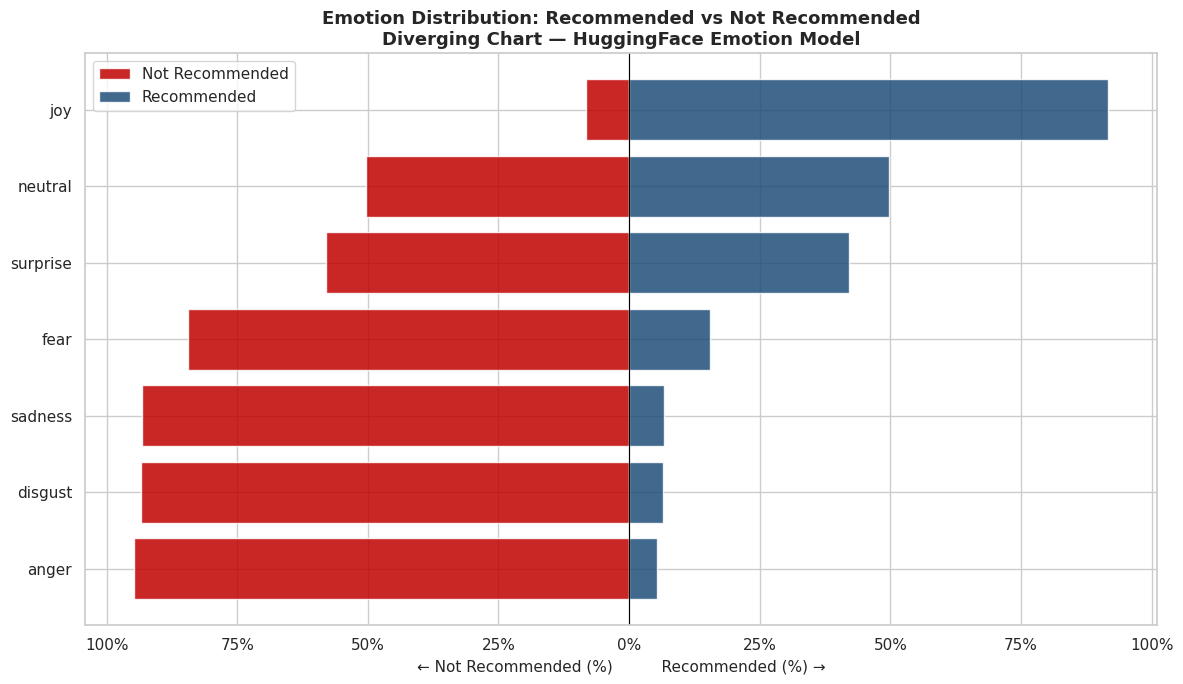

Recommended     0     1
Emotion                
anger        94.7   5.3
disgust      93.4   6.6
sadness      93.3   6.7
fear         84.5  15.5
surprise     58.0  42.0
neutral      50.3  49.7
joy           8.3  91.7


In [43]:
# ============================================================
# PART 4b: Cell 5 — Viz 1: Diverging Emotion Chart
# ============================================================

emotion_counts = df_sample.groupby(['Emotion', 'Recommended']).size().unstack(fill_value=0)
emotion_pct = emotion_counts.div(emotion_counts.sum(axis=1), axis=0) * 100
emotion_pct = emotion_pct.sort_values(1, ascending=True)

fig, ax = plt.subplots(figsize=(12, 7))

# Not recommended goes left (negative), recommended goes right (positive)
ax.barh(emotion_pct.index, -emotion_pct[0],
        color='#C00000', label='Not Recommended', alpha=0.85)
ax.barh(emotion_pct.index, emotion_pct[1],
        color='#1F4E79', label='Recommended', alpha=0.85)

ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('← Not Recommended (%)          Recommended (%) →', fontsize=11)
ax.set_title('Emotion Distribution: Recommended vs Not Recommended\n'
             'Diverging Chart — HuggingFace Emotion Model',
             fontsize=13, fontweight='bold')

# Fix x axis labels to show positive values on both sides
ticks = ax.get_xticks()
ax.set_xticklabels([f'{abs(int(t))}%' for t in ticks])
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

print(emotion_pct.round(1))

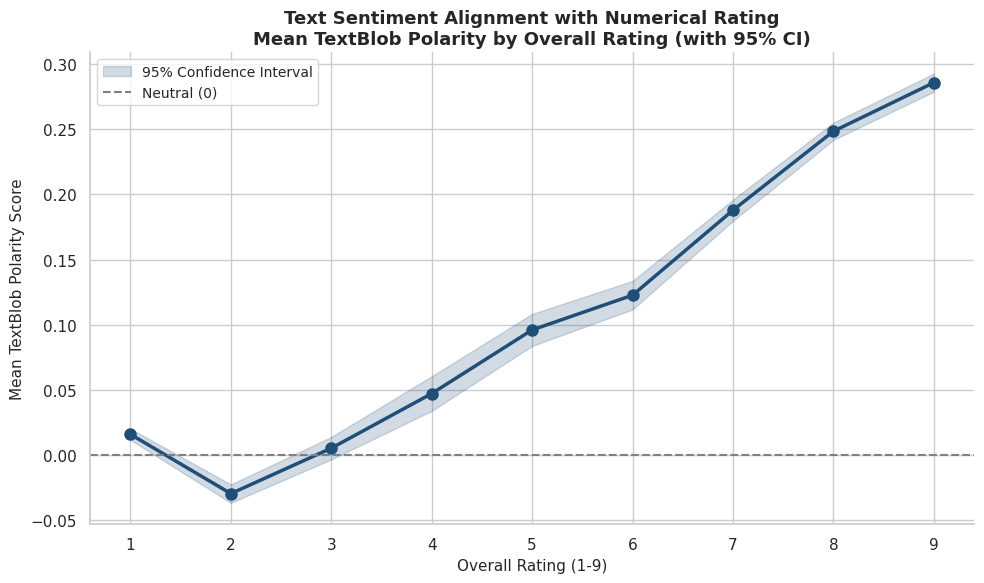

   Overall_Rating   mean     ci  count
0             1.0  0.016  0.004  11595
1             2.0 -0.030  0.007   2296
2             3.0  0.005  0.009   1356
3             4.0  0.047  0.013    859
4             5.0  0.096  0.012    830
5             6.0  0.123  0.011    675
6             7.0  0.188  0.008   1193
7             8.0  0.249  0.007   1757
8             9.0  0.286  0.007   1768


In [44]:
# ============================================================
# PART 4b: Cell 6 — Viz 2: Polarity vs Overall Rating with CI
# ============================================================

polarity_stats = df.groupby('Overall_Rating')['TB_Polarity'].agg(
    ['mean', 'std', 'count']).reset_index()
polarity_stats['se'] = polarity_stats['std'] / np.sqrt(polarity_stats['count'])
polarity_stats['ci'] = 1.96 * polarity_stats['se']

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(polarity_stats['Overall_Rating'], polarity_stats['mean'],
        color='#1F4E79', marker='o', linewidth=2.5, markersize=8)

ax.fill_between(polarity_stats['Overall_Rating'],
                polarity_stats['mean'] - polarity_stats['ci'],
                polarity_stats['mean'] + polarity_stats['ci'],
                alpha=0.2, color='#1F4E79', label='95% Confidence Interval')

ax.axhline(y=0, color='grey', linestyle='--', linewidth=1.5, label='Neutral (0)')
ax.set_xlabel('Overall Rating (1-9)', fontsize=11)
ax.set_ylabel('Mean TextBlob Polarity Score', fontsize=11)
ax.set_title('Text Sentiment Alignment with Numerical Rating\n'
             'Mean TextBlob Polarity by Overall Rating (with 95% CI)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

print(polarity_stats[['Overall_Rating', 'mean', 'ci', 'count']].round(3))

/tmp/ipykernel_7919/3447115757.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  misalign_cases = df.groupby('Rating_Band', observed=True).apply(


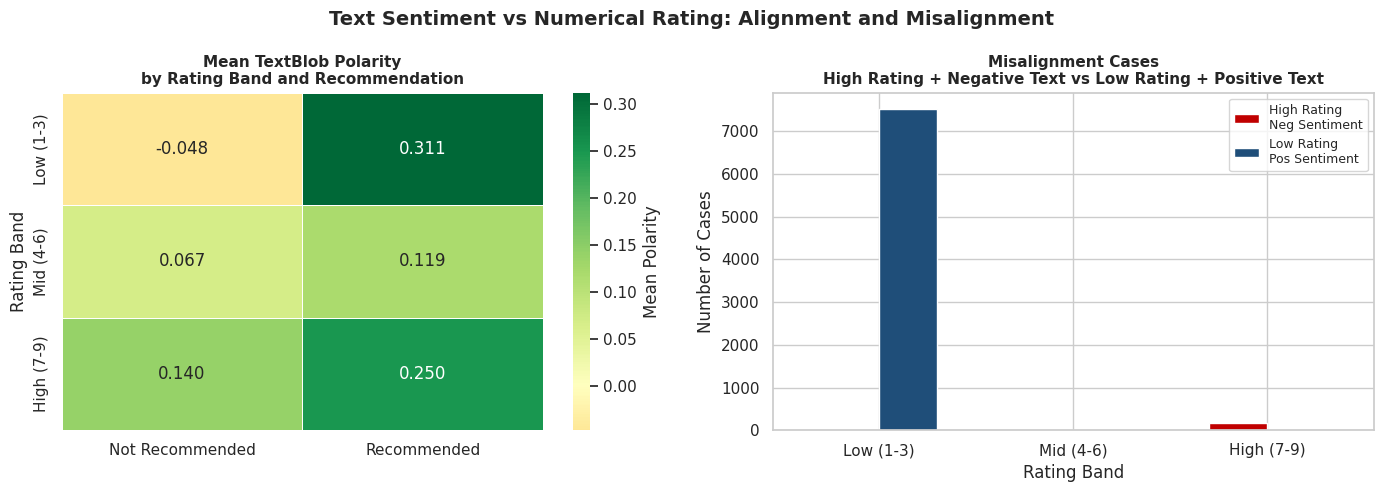


Mean polarity by rating band:
             Not Recommended  Recommended
Rating_Band                              
Low (1-3)             -0.048        0.311
Mid (4-6)              0.067        0.119
High (7-9)             0.140        0.250


In [45]:
# ============================================================
# PART 4b: Cell 9 — Viz 5: Sentiment-Rating Misalignment Heatmap
# ============================================================

# Create rating bands
df['Rating_Band'] = pd.cut(df['Overall_Rating'],
                           bins=[0, 3, 6, 9],
                           labels=['Low (1-3)', 'Mid (4-6)', 'High (7-9)'])

# Mean polarity by rating band and recommendation
misalign = df.groupby(['Rating_Band', 'Recommended'],
                      observed=True)['TB_Polarity'].mean().unstack()
misalign.columns = ['Not Recommended', 'Recommended']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap
sns.heatmap(misalign, annot=True, fmt='.3f',
            cmap='RdYlGn', center=0,
            linewidths=0.5, ax=axes[0],
            cbar_kws={'label': 'Mean Polarity'})
axes[0].set_title('Mean TextBlob Polarity\nby Rating Band and Recommendation',
                  fontsize=11, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Rating Band')

# Misalignment cases — high rating but negative polarity
misalign_cases = df.groupby('Rating_Band', observed=True).apply(
    lambda x: pd.Series({
        'High Rating\nNeg Sentiment': ((x['Overall_Rating'] >= 7) &
                                       (x['TB_Polarity'] < 0)).sum(),
        'Low Rating\nPos Sentiment': ((x['Overall_Rating'] <= 3) &
                                      (x['TB_Polarity'] > 0)).sum()
    })
).reset_index()

misalign_cases.plot(x='Rating_Band', kind='bar',
                    color=['#C00000', '#1F4E79'],
                    edgecolor='white', ax=axes[1], width=0.6)
axes[1].set_title('Misalignment Cases\nHigh Rating + Negative Text vs Low Rating + Positive Text',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('Rating Band')
axes[1].set_ylabel('Number of Cases')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(fontsize=9)

plt.suptitle('Text Sentiment vs Numerical Rating: Alignment and Misalignment',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nMean polarity by rating band:")
print(misalign.round(3))

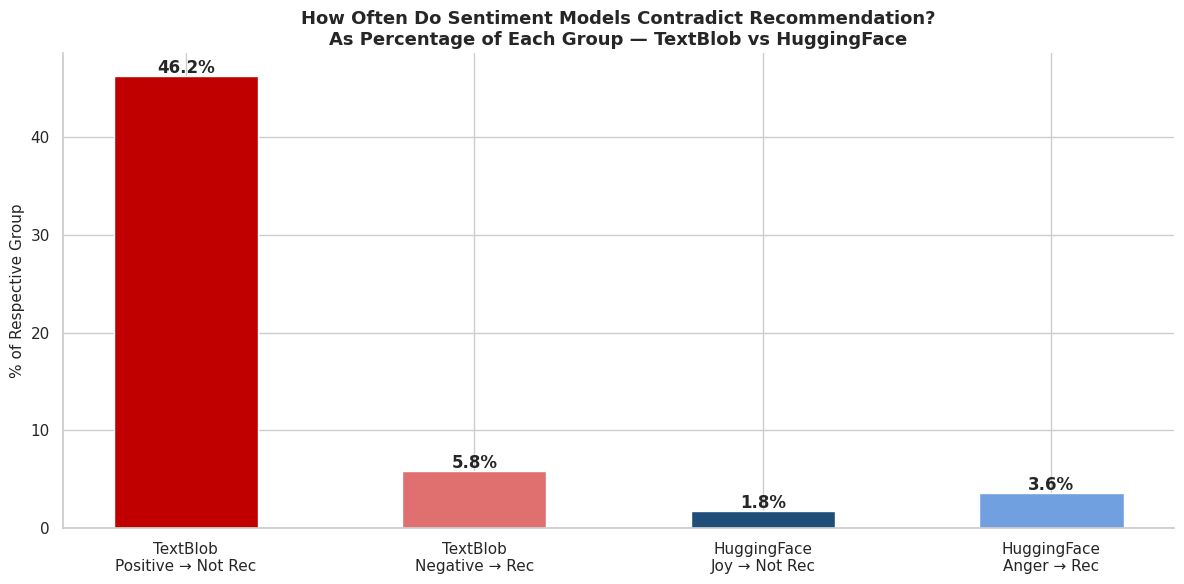

TextBlob Positive → Not Rec: 46.2%
TextBlob Negative → Rec: 5.8%
HuggingFace Joy → Not Rec: 1.8%
HuggingFace Anger → Rec: 3.6%


In [46]:
# ============================================================
# PART 4b: Cell 7 — Viz 3: Contradiction Proportional Comparison
# ============================================================

total_sample = len(df_sample)
total_rec = len(df_sample[df_sample['Recommended'] == 1])
total_not_rec = len(df_sample[df_sample['Recommended'] == 0])

tb_pos_not_rec = len(df_sample[
    (df_sample['TB_Sentiment'] == 'Positive') &
    (df_sample['Recommended'] == 0)])
tb_neg_rec = len(df_sample[
    (df_sample['TB_Sentiment'] == 'Negative') &
    (df_sample['Recommended'] == 1)])
hf_joy_not_rec = len(df_sample[
    (df_sample['Emotion'] == 'joy') &
    (df_sample['Recommended'] == 0)])
hf_neg_rec = len(df_sample[
    (df_sample['Emotion'].isin(['anger', 'disgust'])) &
    (df_sample['Recommended'] == 1)])

# As percentage of their group
data = {
    'TextBlob\nPositive → Not Rec': tb_pos_not_rec / total_not_rec * 100,
    'TextBlob\nNegative → Rec': tb_neg_rec / total_rec * 100,
    'HuggingFace\nJoy → Not Rec': hf_joy_not_rec / total_not_rec * 100,
    'HuggingFace\nAnger → Rec': hf_neg_rec / total_rec * 100
}

colors = ['#C00000', '#E07070', '#1F4E79', '#70A0E0']
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(data.keys(), data.values(),
              color=colors, edgecolor='white', width=0.5)

for bar, val in zip(bars, data.values()):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.3,
            f'{val:.1f}%', ha='center',
            fontsize=12, fontweight='bold')

ax.set_ylabel('% of Respective Group', fontsize=11)
ax.set_title('How Often Do Sentiment Models Contradict Recommendation?\n'
             'As Percentage of Each Group — TextBlob vs HuggingFace',
             fontsize=13, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

for k, v in data.items():
    print(f"{k.replace(chr(10), ' ')}: {v:.1f}%")

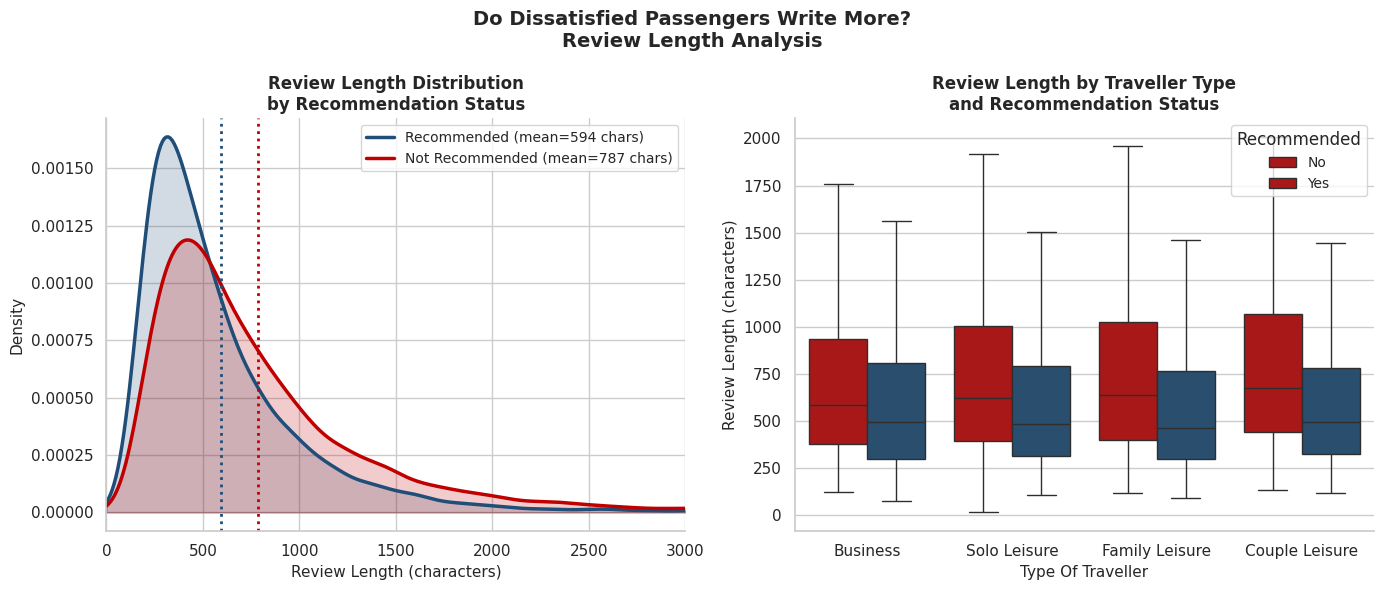

Mean review length — Recommended:     594 chars
Mean review length — Not Recommended: 787 chars
Difference: 193 chars (32.5% longer)


In [47]:
# ============================================================
# PART 4b: Cell 10 — Review Length by Recommendation ( Corrected by chat gpt)
# ============================================================

df['Review_Length'] = df['Review'].str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# KDE plot
from scipy.stats import gaussian_kde

rec_len = df[df['Recommended']==1]['Review_Length'].dropna()
not_rec_len = df[df['Recommended']==0]['Review_Length'].dropna()

x_range = np.linspace(0, 3000, 300)
kde_rec = gaussian_kde(rec_len)
kde_not = gaussian_kde(not_rec_len)

axes[0].plot(x_range, kde_rec(x_range), color='#1F4E79',
             linewidth=2.5, label=f'Recommended (mean={rec_len.mean():.0f} chars)')
axes[0].fill_between(x_range, kde_rec(x_range), alpha=0.2, color='#1F4E79')
axes[0].plot(x_range, kde_not(x_range), color='#C00000',
             linewidth=2.5, label=f'Not Recommended (mean={not_rec_len.mean():.0f} chars)')
axes[0].fill_between(x_range, kde_not(x_range), alpha=0.2, color='#C00000')
axes[0].axvline(x=rec_len.mean(), color='#1F4E79', linestyle=':', linewidth=2)
axes[0].axvline(x=not_rec_len.mean(), color='#C00000', linestyle=':', linewidth=2)
axes[0].set_xlabel('Review Length (characters)', fontsize=11)
axes[0].set_ylabel('Density', fontsize=11)
axes[0].set_title('Review Length Distribution\nby Recommendation Status',
                  fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].set_xlim(0, 3000)

# Box plot by traveller type
df_known = df[df['Type Of Traveller'] != 'Unknown']
order = df_known.groupby('Type Of Traveller')['Review_Length'].mean().sort_values().index

sns.boxplot(data=df_known, x='Type Of Traveller', y='Review_Length',
            hue='Recommended', palette={0: '#C00000', 1: '#1F4E79'},
            order=order, ax=axes[1], showfliers=False)
axes[1].set_title('Review Length by Traveller Type\nand Recommendation Status',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Type Of Traveller', fontsize=11)
axes[1].set_ylabel('Review Length (characters)', fontsize=11)
axes[1].legend(title='Recommended', labels=['No', 'Yes'], fontsize=10)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.suptitle('Do Dissatisfied Passengers Write More?\nReview Length Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Mean review length — Recommended:     {rec_len.mean():.0f} chars")
print(f"Mean review length — Not Recommended: {not_rec_len.mean():.0f} chars")
print(f"Difference: {not_rec_len.mean() - rec_len.mean():.0f} chars ({(not_rec_len.mean()-rec_len.mean())/rec_len.mean()*100:.1f}% longer)")

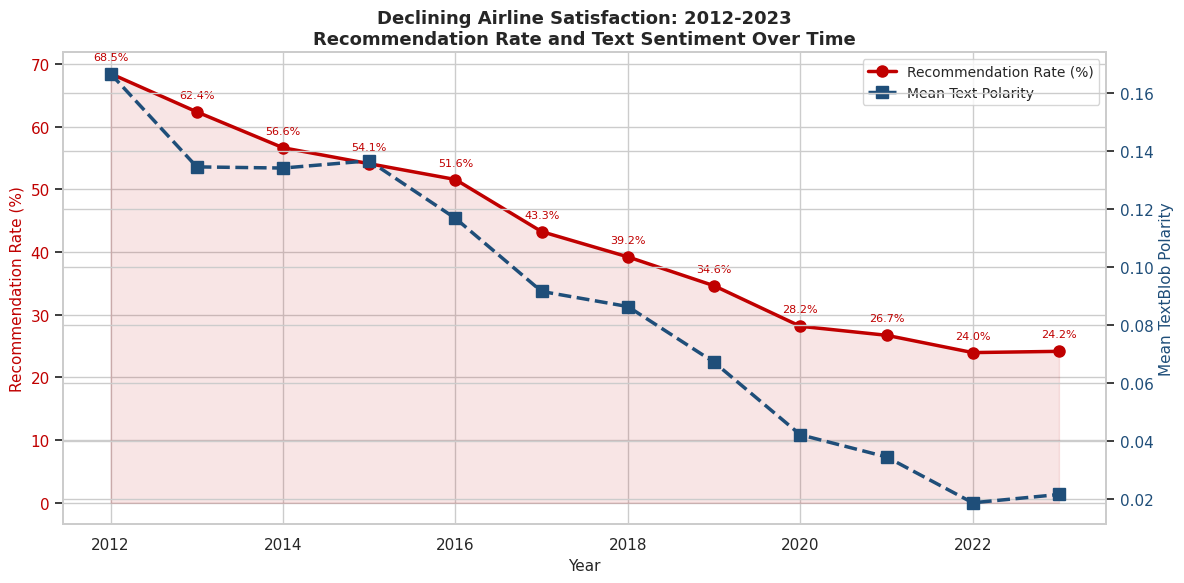

  Year  Rec_Rate  Mean_Polarity  Count
2012.0    68.471          0.167    314
2013.0    62.366          0.135    372
2014.0    56.643          0.134    429
2015.0    54.098          0.137    854
2016.0    51.574          0.117    921
2017.0    43.258          0.092    890
2018.0    39.231          0.086   1300
2019.0    34.626          0.067   2244
2020.0    28.160          0.042   1147
2021.0    26.724          0.035    812
2022.0    23.961          0.019   2984
2023.0    24.162          0.022   4267


In [48]:
# ============================================================
# PART 4b: Cell 11 — Recommendation Rate and Sentiment Over Time
# ============================================================

df['Review Date'] = pd.to_datetime(df['Review Date'], dayfirst=True, errors='coerce')
df['Year'] = df['Review Date'].dt.year

yearly = df[df['Year'] >= 2012].groupby('Year').agg(
    Rec_Rate=('Recommended', 'mean'),
    Mean_Polarity=('TB_Polarity', 'mean'),
    Count=('Recommended', 'count')
).reset_index()
yearly['Rec_Rate'] = yearly['Rec_Rate'] * 100

fig, ax1 = plt.subplots(figsize=(12, 6))

# Recommendation rate line
ax1.plot(yearly['Year'], yearly['Rec_Rate'],
         color='#C00000', marker='o', linewidth=2.5,
         markersize=8, label='Recommendation Rate (%)')
ax1.fill_between(yearly['Year'], yearly['Rec_Rate'],
                 alpha=0.1, color='#C00000')
ax1.set_xlabel('Year', fontsize=11)
ax1.set_ylabel('Recommendation Rate (%)', color='#C00000', fontsize=11)
ax1.tick_params(axis='y', labelcolor='#C00000')

for _, row in yearly.iterrows():
    ax1.annotate(f"{row['Rec_Rate']:.1f}%",
                 (row['Year'], row['Rec_Rate']),
                 textcoords='offset points',
                 xytext=(0, 10), ha='center',
                 fontsize=8, color='#C00000')

# Polarity line
ax2 = ax1.twinx()
ax2.plot(yearly['Year'], yearly['Mean_Polarity'],
         color='#1F4E79', marker='s', linewidth=2.5,
         markersize=8, linestyle='--', label='Mean Text Polarity')
ax2.set_ylabel('Mean TextBlob Polarity', color='#1F4E79', fontsize=11)
ax2.tick_params(axis='y', labelcolor='#1F4E79')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2,
           loc='upper right', fontsize=10)

plt.title('Declining Airline Satisfaction: 2012-2023\n'
          'Recommendation Rate and Text Sentiment Over Time',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(yearly[['Year', 'Rec_Rate', 'Mean_Polarity', 'Count']].round(3).to_string(index=False))

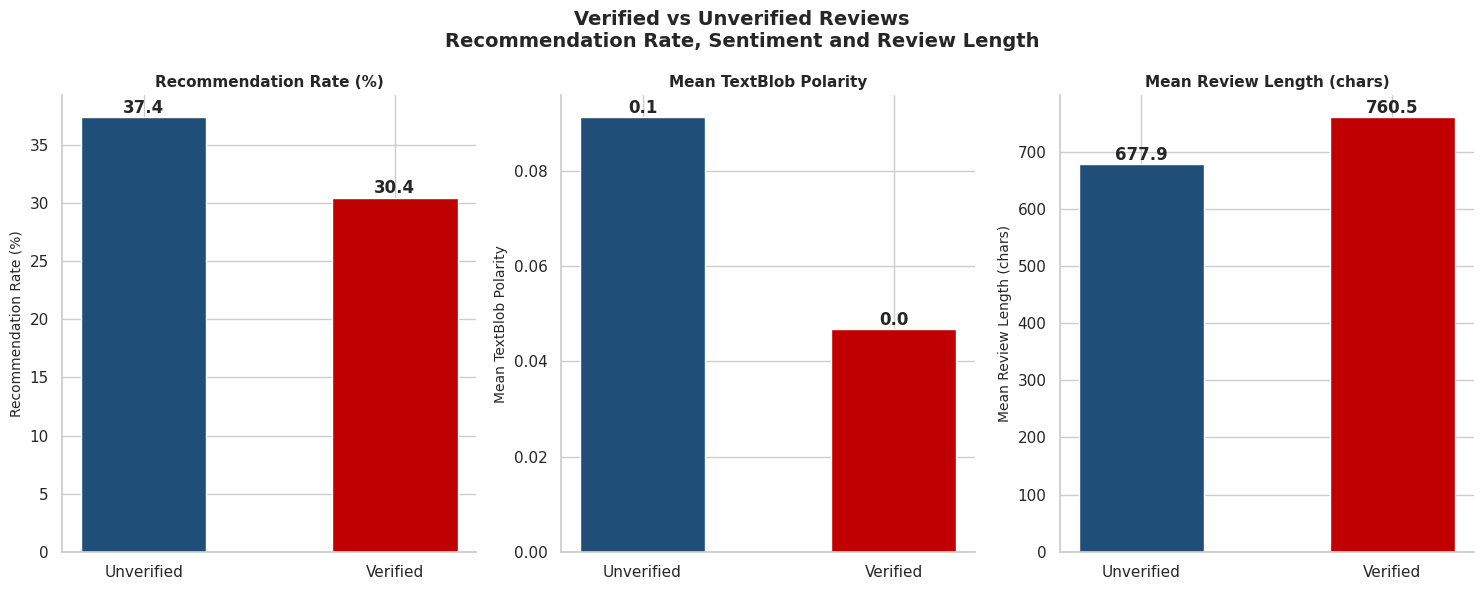

  Verified  Rec_Rate  Mean_Polarity  Mean_Length  Count
Unverified    37.386          0.091      677.879  10849
  Verified    30.441          0.047      760.506  12322


In [49]:
# ============================================================
# PART 4b: Cell 12 — Verified vs Unverified Analysis
# ============================================================

verified_stats = df.groupby('Verified').agg(
    Rec_Rate=('Recommended', 'mean'),
    Mean_Polarity=('TB_Polarity', 'mean'),
    Mean_Length=('Review_Length', 'mean'),
    Count=('Recommended', 'count')
).reset_index()
verified_stats['Rec_Rate'] = verified_stats['Rec_Rate'] * 100
verified_stats['Verified'] = verified_stats['Verified'].map(
    {True: 'Verified', False: 'Unverified'})

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

metrics = ['Rec_Rate', 'Mean_Polarity', 'Mean_Length']
titles = ['Recommendation Rate (%)',
          'Mean TextBlob Polarity',
          'Mean Review Length (chars)']
colors = ['#1F4E79', '#C00000']

for i, (metric, title) in enumerate(zip(metrics, titles)):
    bars = axes[i].bar(verified_stats['Verified'],
                       verified_stats[metric],
                       color=colors, edgecolor='white', width=0.5)
    for bar, val in zip(bars, verified_stats[metric]):
        axes[i].text(bar.get_x() + bar.get_width()/2,
                     bar.get_height() + max(verified_stats[metric]) * 0.01,
                     f'{val:.1f}', ha='center',
                     fontsize=12, fontweight='bold')
    axes[i].set_title(title, fontsize=11, fontweight='bold')
    axes[i].set_ylabel(title, fontsize=10)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

plt.suptitle('Verified vs Unverified Reviews\n'
             'Recommendation Rate, Sentiment and Review Length',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(verified_stats[['Verified', 'Rec_Rate', 'Mean_Polarity',
                       'Mean_Length', 'Count']].round(3).to_string(index=False))

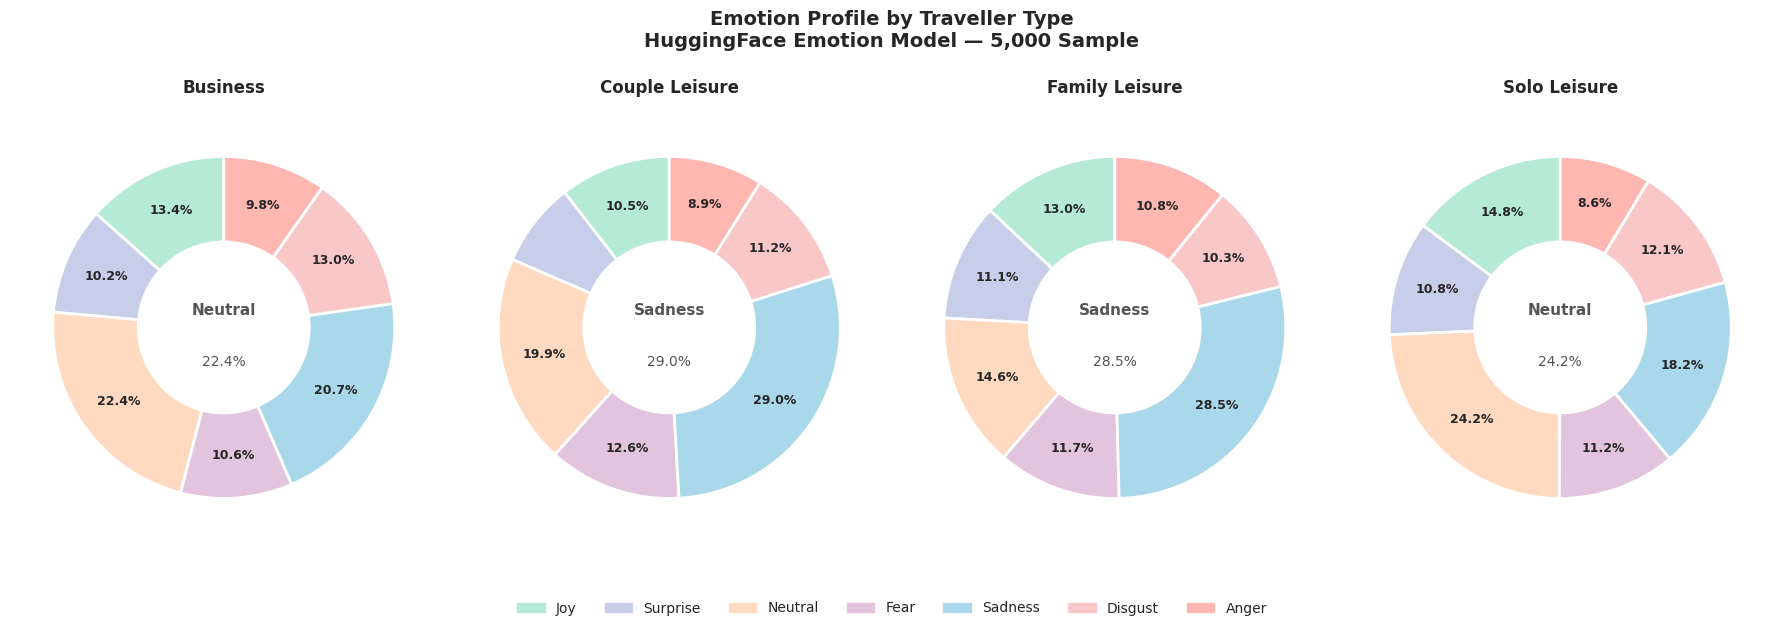


Emotion distribution by traveller type (%):
Emotion             joy  surprise  neutral  fear  sadness  disgust  anger
Type Of Traveller                                                        
Business           13.4      10.2     22.4  10.6     20.7     13.0    9.8
Couple Leisure     10.5       8.0     19.9  12.6     29.0     11.2    8.9
Family Leisure     13.0      11.1     14.6  11.7     28.5     10.3   10.8
Solo Leisure       14.8      10.8     24.2  11.2     18.2     12.1    8.6


In [50]:
# ============================================================
# PART 4b: Cell 13 — Emotion Profile by Traveller Type
# Small Multiples Donut Charts with Pastel Colours
# ============================================================

import matplotlib.patches as mpatches


df_known_sample = df_sample[df_sample['Type Of Traveller'] != 'Unknown']

emotion_traveller = df_known_sample.groupby(
    ['Type Of Traveller', 'Emotion']).size().unstack(fill_value=0)
emotion_pct = emotion_traveller.div(
    emotion_traveller.sum(axis=1), axis=0) * 100

emotion_order = ['joy', 'surprise', 'neutral', 'fear', 'sadness', 'disgust', 'anger']
emotion_pct = emotion_pct[emotion_order]

pastel_colors = {
    'joy':      '#B5EAD7',
    'surprise': '#C7CEEA',
    'neutral':  '#FFDAC1',
    'fear':     '#E2C4DE',
    'sadness':  '#A8D8EA',
    'disgust':  '#F9C7C8',
    'anger':    '#FFB7B2'
}
colors = [pastel_colors[e] for e in emotion_order]

traveller_types = emotion_pct.index.tolist()
fig, axes = plt.subplots(1, 4, figsize=(18, 6))

for i, traveller in enumerate(traveller_types):
    values = emotion_pct.loc[traveller].values
    dominant_emotion = emotion_pct.loc[traveller].idxmax()
    dominant_pct = emotion_pct.loc[traveller].max()

    wedges, texts, autotexts = axes[i].pie(
        values,
        labels=None,
        colors=colors,
        autopct=lambda p: f'{p:.1f}%' if p >= 8 else '',
        pctdistance=0.75,
        startangle=90,
        wedgeprops=dict(width=0.5, edgecolor='white', linewidth=2)
    )

    for autotext in autotexts:
        autotext.set_fontsize(9)
        autotext.set_fontweight('bold')

    # Centre text showing dominant emotion
    axes[i].text(0, 0.1, dominant_emotion.capitalize(),
                 ha='center', va='center',
                 fontsize=11, fontweight='bold', color='#555555')
    axes[i].text(0, -0.2, f'{dominant_pct:.1f}%',
                 ha='center', va='center',
                 fontsize=10, color='#555555')

    axes[i].set_title(traveller, fontsize=12,
                      fontweight='bold', pad=15)

# Shared legend
legend_patches = [mpatches.Patch(color=pastel_colors[e],
                                  label=e.capitalize())
                  for e in emotion_order]
fig.legend(handles=legend_patches,
           loc='lower center',
           ncol=7,
           fontsize=10,
           frameon=False,
           bbox_to_anchor=(0.5, -0.05))

plt.suptitle('Emotion Profile by Traveller Type\n'
             'HuggingFace Emotion Model — 5,000 Sample',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nEmotion distribution by traveller type (%):")
print(emotion_pct.round(1))

In [51]:
# ============================================================
# PART 4b: Cell 14 — TF-IDF Vectorisation
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer

df_text = df[['Review_Cleaned', 'Recommended']].dropna()

print("=" * 50)
print("TEXT MODELLING DATASET")
print("=" * 50)
print(f"Total rows: {len(df_text)}")
print(f"Class distribution:\n{df_text['Recommended'].value_counts()}")

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.95
)

X_text = tfidf.fit_transform(df_text['Review_Cleaned'])
y_text = df_text['Recommended']

print(f"\nTF-IDF matrix shape: {X_text.shape}")
print(f"Vocabulary size: {len(tfidf.vocabulary_)}")

TEXT MODELLING DATASET
Total rows: 23171
Class distribution:
Recommended
0    15364
1     7807
Name: count, dtype: int64

TF-IDF matrix shape: (23171, 5000)
Vocabulary size: 5000


In [52]:
# ============================================================
# PART 4b: Cell 15 — Train/Test Split
# ============================================================

X_text_train, X_text_test, y_text_train, y_text_test = train_test_split(
    X_text, y_text,
    test_size=0.3,
    random_state=40481810,
    stratify=y_text
)

print("=" * 50)
print("TRAIN/TEST SPLIT")
print("=" * 50)
print(f"Training set: {X_text_train.shape}")
print(f"Test set:     {X_text_test.shape}")
print(f"\nTraining class distribution:")
print(pd.Series(y_text_train).value_counts())
print(f"\nTest class distribution:")
print(pd.Series(y_text_test).value_counts())

TRAIN/TEST SPLIT
Training set: (16219, 5000)
Test set:     (6952, 5000)

Training class distribution:
Recommended
0    10754
1     5465
Name: count, dtype: int64

Test class distribution:
Recommended
0    4610
1    2342
Name: count, dtype: int64


In [53]:
# ============================================================
# PART 4b: Cell 16 — Train RF and LR on Text Features
# ============================================================

# --- Random Forest ---
rf_text = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=40481810
)
rf_text.fit(X_text_train, y_text_train)
rf_text_prob = rf_text.predict_proba(X_text_test)[:, 1]
rf_text_pred = (rf_text_prob >= 0.5).astype(int)

print("=" * 50)
print("RANDOM FOREST — TEXT FEATURES")
print("=" * 50)
print(classification_report(y_text_test, rf_text_pred))
print(f"ROC-AUC: {roc_auc_score(y_text_test, rf_text_prob):.4f}")
print(f"PR-AUC:  {average_precision_score(y_text_test, rf_text_prob):.4f}")

# --- Logistic Regression ---
lr_text = LogisticRegression(
    C=1.0,
    class_weight='balanced',
    max_iter=1000,
    random_state=40481810
)
lr_text.fit(X_text_train, y_text_train)
lr_text_prob = lr_text.predict_proba(X_text_test)[:, 1]
lr_text_pred = (lr_text_prob >= 0.5).astype(int)

print("\n" + "=" * 50)
print("LOGISTIC REGRESSION — TEXT FEATURES")
print("=" * 50)
print(classification_report(y_text_test, lr_text_pred))
print(f"ROC-AUC: {roc_auc_score(y_text_test, lr_text_prob):.4f}")
print(f"PR-AUC:  {average_precision_score(y_text_test, lr_text_prob):.4f}")

RANDOM FOREST — TEXT FEATURES
              precision    recall  f1-score   support

           0       0.94      0.85      0.89      4610
           1       0.75      0.89      0.81      2342

    accuracy                           0.86      6952
   macro avg       0.84      0.87      0.85      6952
weighted avg       0.87      0.86      0.86      6952

ROC-AUC: 0.9287
PR-AUC:  0.8491

LOGISTIC REGRESSION — TEXT FEATURES
              precision    recall  f1-score   support

           0       0.95      0.91      0.93      4610
           1       0.84      0.90      0.87      2342

    accuracy                           0.91      6952
   macro avg       0.89      0.90      0.90      6952
weighted avg       0.91      0.91      0.91      6952

ROC-AUC: 0.9578
PR-AUC:  0.9043


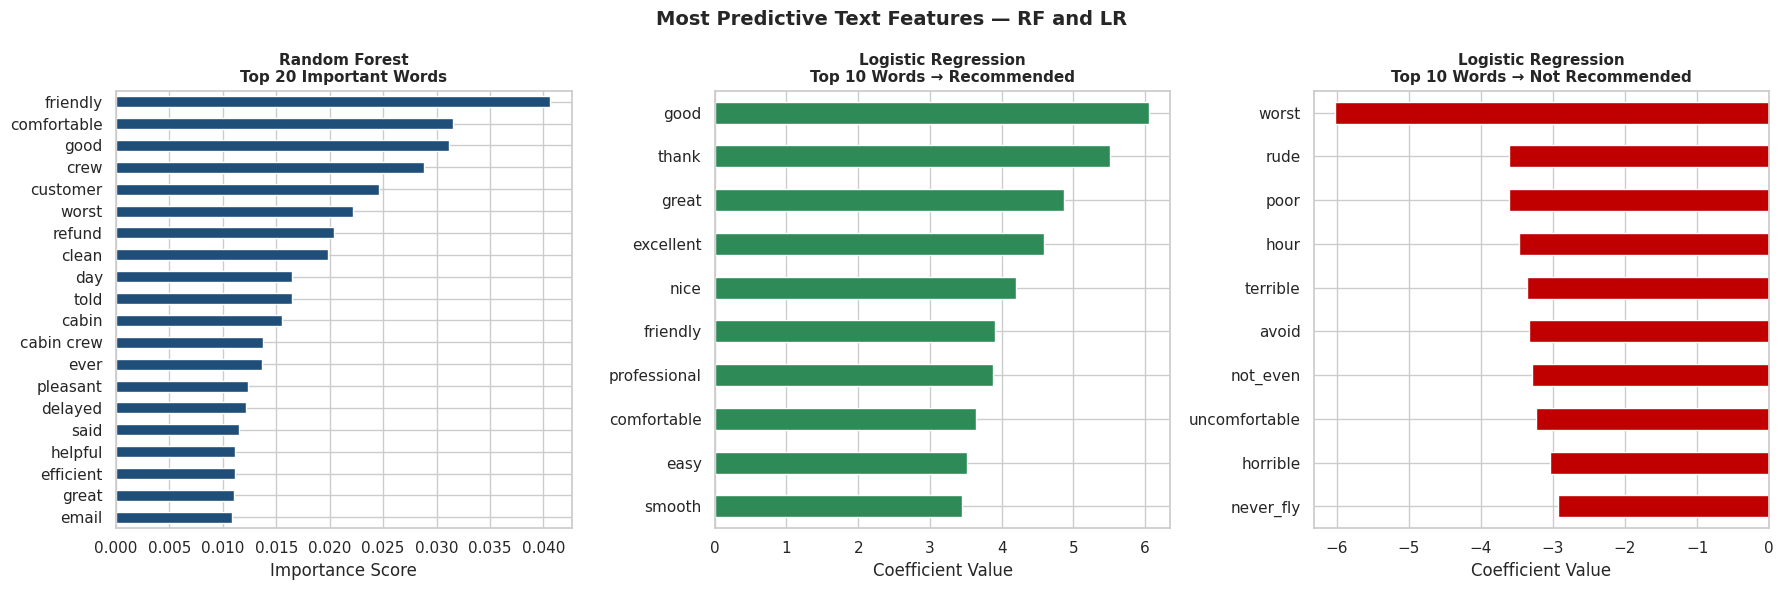

RF Top 20 features:
friendly       0.0406
comfortable    0.0315
good           0.0311
crew           0.0289
customer       0.0247
worst          0.0222
refund         0.0204
clean          0.0199
day            0.0165
told           0.0165
cabin          0.0156
cabin crew     0.0138
ever           0.0136
pleasant       0.0123
delayed        0.0122
said           0.0116
helpful        0.0111
efficient      0.0111
great          0.0111
email          0.0109
dtype: float64

LR Top 10 positive (→ Recommended):
good            6.0497
thank           5.5152
great           4.8692
excellent       4.5893
nice            4.1968
friendly        3.9032
professional    3.8756
comfortable     3.6469
easy            3.5147
smooth          3.4426
dtype: float64

LR Top 10 negative (→ Not Recommended):
worst           -6.0193
rude            -3.6079
poor            -3.6070
hour            -3.4640
terrible        -3.3633
avoid           -3.3373
not_even        -3.2879
uncomfortable   -3.2358
horrible  

In [54]:
# ============================================================
# PART 4b: Cell 17 — Top Predictive Text Features
# ============================================================

# --- RF Top Features ---
rf_text_importances = pd.Series(
    rf_text.feature_importances_,
    index=tfidf.get_feature_names_out()
).sort_values(ascending=False).head(20)

# --- LR Top Features ---
lr_text_coef = pd.Series(
    lr_text.coef_[0],
    index=tfidf.get_feature_names_out()
)
lr_top_pos = lr_text_coef.sort_values(ascending=False).head(10)
lr_top_neg = lr_text_coef.sort_values(ascending=True).head(10)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# RF importance
rf_text_importances.sort_values().plot(
    kind='barh', ax=axes[0],
    color='#1F4E79', edgecolor='white')
axes[0].set_title('Random Forest\nTop 20 Important Words',
                  fontsize=11, fontweight='bold')
axes[0].set_xlabel('Importance Score')

# LR positive coefficients
lr_top_pos.sort_values().plot(
    kind='barh', ax=axes[1],
    color='#2E8B57', edgecolor='white')
axes[1].set_title('Logistic Regression\nTop 10 Words → Recommended',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('Coefficient Value')

# LR negative coefficients
lr_top_neg.sort_values(ascending=False).plot(
    kind='barh', ax=axes[2],
    color='#C00000', edgecolor='white')
axes[2].set_title('Logistic Regression\nTop 10 Words → Not Recommended',
                  fontsize=11, fontweight='bold')
axes[2].set_xlabel('Coefficient Value')

plt.suptitle('Most Predictive Text Features — RF and LR',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("RF Top 20 features:")
print(rf_text_importances.round(4))
print("\nLR Top 10 positive (→ Recommended):")
print(lr_top_pos.round(4))
print("\nLR Top 10 negative (→ Not Recommended):")
print(lr_top_neg.round(4))

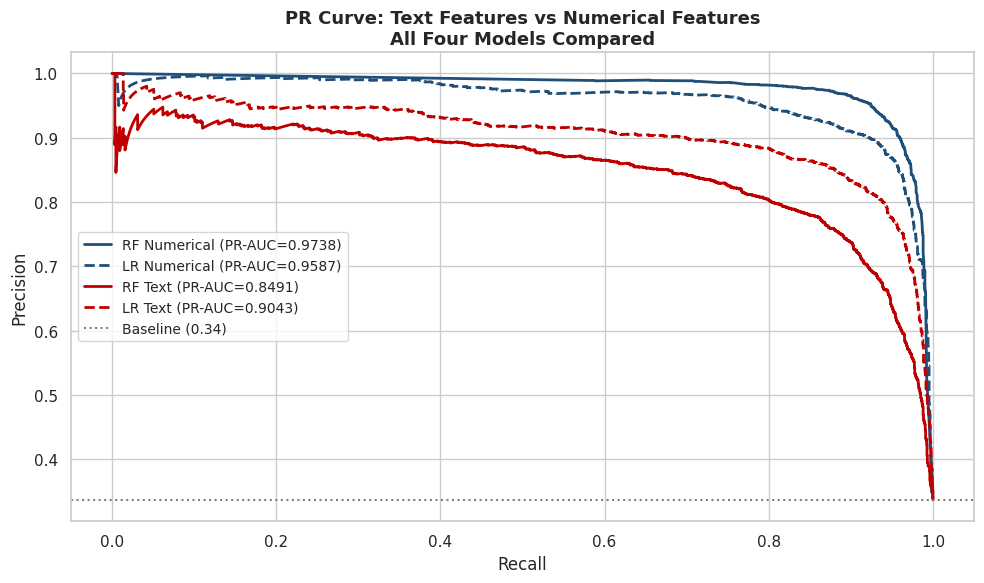

In [55]:
# ============================================================
# PART 4b: Cell 18 — PR Curve: Text vs Numerical Models
# ============================================================

rf_num_prec, rf_num_rec, _ = precision_recall_curve(y_test, rf_prob)
lr_num_prec, lr_num_rec, _ = precision_recall_curve(y_test, lr_prob)
rf_txt_prec, rf_txt_rec, _ = precision_recall_curve(y_text_test, rf_text_prob)
lr_txt_prec, lr_txt_rec, _ = precision_recall_curve(y_text_test, lr_text_prob)

baseline = y_text_test.sum() / len(y_text_test)

plt.figure(figsize=(10, 6))
plt.plot(rf_num_rec, rf_num_prec, color='#1F4E79', linewidth=2,
         label=f'RF Numerical (PR-AUC={average_precision_score(y_test, rf_prob):.4f})')
plt.plot(lr_num_rec, lr_num_prec, color='#1F4E79', linewidth=2,
         linestyle='--',
         label=f'LR Numerical (PR-AUC={average_precision_score(y_test, lr_prob):.4f})')
plt.plot(rf_txt_rec, rf_txt_prec, color='#C00000', linewidth=2,
         label=f'RF Text (PR-AUC={average_precision_score(y_text_test, rf_text_prob):.4f})')
plt.plot(lr_txt_rec, lr_txt_prec, color='#C00000', linewidth=2,
         linestyle='--',
         label=f'LR Text (PR-AUC={average_precision_score(y_text_test, lr_text_prob):.4f})')
plt.axhline(y=baseline, color='grey', linestyle=':', linewidth=1.5,
            label=f'Baseline ({baseline:.2f})')

plt.title('PR Curve: Text Features vs Numerical Features\nAll Four Models Compared',
          fontsize=13, fontweight='bold')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

In [56]:
# ============================================================
# PART 4c: Cell 19 — Combine Numerical + Categorical + Text Features
# Strategy 1: Feature Concatenation (with categorial variables)
# ============================================================

from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import LabelEncoder

# --- Columns to use ---
numerical_cols_model = feature_cols
categorical_cols = ['Type Of Traveller', 'Seat Type', 'Verified']

all_cols = numerical_cols_model + categorical_cols + ['Recommended', 'Review_Cleaned']
df_combined = df[all_cols].dropna()

print("=" * 50)
print("COMBINED DATASET")
print("=" * 50)
print(f"Shape: {df_combined.shape}")
print(f"Class distribution:\n{df_combined['Recommended'].value_counts()}")

# --- Encode categorical columns ---
# One-hot encoding — creates binary columns for each category
# e.g. Seat Type → Economy=1/0, Business=1/0, First=1/0, Premium=1/0
df_encoded = pd.get_dummies(
    df_combined[categorical_cols],
    drop_first=False
).astype(float)

print(f"\nCategorical features after encoding: {df_encoded.shape[1]}")
print(f"Encoded columns: {list(df_encoded.columns)}")

# --- TF-IDF on text ---
tfidf_combined = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.95
)
X_text_combined = tfidf_combined.fit_transform(df_combined['Review_Cleaned'])

# --- Combine all three ---
X_num_combined = csr_matrix(df_combined[numerical_cols_model].values)
X_cat_combined = csr_matrix(df_encoded.values)
X_combined = hstack([X_num_combined, X_cat_combined, X_text_combined])
y_combined = df_combined['Recommended']

print(f"\nNumerical features:   {X_num_combined.shape[1]}")
print(f"Categorical features: {X_cat_combined.shape[1]}")
print(f"Text features:        {X_text_combined.shape[1]}")
print(f"Combined shape:       {X_combined.shape}")

COMBINED DATASET
Shape: (22329, 12)
Class distribution:
Recommended
0    14527
1     7802
Name: count, dtype: int64

Categorical features after encoding: 11
Encoded columns: ['Verified', 'Type Of Traveller_Business', 'Type Of Traveller_Couple Leisure', 'Type Of Traveller_Family Leisure', 'Type Of Traveller_Solo Leisure', 'Type Of Traveller_Unknown', 'Seat Type_Business Class', 'Seat Type_Economy Class', 'Seat Type_First Class', 'Seat Type_Premium Economy', 'Seat Type_Unknown']

Numerical features:   7
Categorical features: 11
Text features:        5000
Combined shape:       (22329, 5018)


In [57]:
# ============================================================
# PART 4c: Cell 20 — Train/Test Split
# ============================================================

X_comb_train, X_comb_test, y_comb_train, y_comb_test = train_test_split(
    X_combined, y_combined,
    test_size=0.3,
    random_state=40481810,
    stratify=y_combined
)

print("=" * 50)
print("COMBINED TRAIN/TEST SPLIT")
print("=" * 50)
print(f"Training set: {X_comb_train.shape}")
print(f"Test set:     {X_comb_test.shape}")

COMBINED TRAIN/TEST SPLIT
Training set: (15630, 5018)
Test set:     (6699, 5018)


In [58]:
# ============================================================
# PART 4c: Cell 21 — Train Combined Models
# ============================================================

# --- Random Forest ---
rf_combined = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=40481810
)
rf_combined.fit(X_comb_train, y_comb_train)
rf_comb_prob = rf_combined.predict_proba(X_comb_test)[:, 1]
rf_comb_pred = (rf_comb_prob >= 0.5).astype(int)

print("=" * 50)
print("RANDOM FOREST — COMBINED FEATURES")
print("=" * 50)
print(classification_report(y_comb_test, rf_comb_pred))
print(f"PR-AUC: {average_precision_score(y_comb_test, rf_comb_prob):.4f}")

# --- Logistic Regression ---
lr_combined = LogisticRegression(
    C=1.0,
    class_weight='balanced',
    max_iter=1000,
    random_state=40481810
)
lr_combined.fit(X_comb_train, y_comb_train)
lr_comb_prob = lr_combined.predict_proba(X_comb_test)[:, 1]
lr_comb_pred = (lr_comb_prob >= 0.5).astype(int)

print("\n" + "=" * 50)
print("LOGISTIC REGRESSION — COMBINED FEATURES")
print("=" * 50)
print(classification_report(y_comb_test, lr_comb_pred))
print(f"PR-AUC: {average_precision_score(y_comb_test, lr_comb_prob):.4f}")

RANDOM FOREST — COMBINED FEATURES
              precision    recall  f1-score   support

           0       0.98      0.93      0.95      4358
           1       0.88      0.96      0.92      2341

    accuracy                           0.94      6699
   macro avg       0.93      0.94      0.94      6699
weighted avg       0.94      0.94      0.94      6699

PR-AUC: 0.9649

LOGISTIC REGRESSION — COMBINED FEATURES
              precision    recall  f1-score   support

           0       0.98      0.95      0.96      4358
           1       0.91      0.96      0.93      2341

    accuracy                           0.95      6699
   macro avg       0.94      0.95      0.95      6699
weighted avg       0.95      0.95      0.95      6699

PR-AUC: 0.9767


In [59]:
# ============================================================
# PART 4c: Cell 22 — Full Performance Comparison
# ============================================================

print("=" * 50)
print("FULL MODEL COMPARISON — ALL FEATURE TYPES")
print("=" * 50)
print(f"{'Model':<30} {'PR-AUC':<10} {'Accuracy'}")
print("-" * 50)

models = {
    'RF — Numerical':  (rf_prob,      y_test,      rf_pred),
    'LR — Numerical':  (lr_prob,      y_test,      lr_pred),
    'RF — Text':       (rf_text_prob, y_text_test, rf_text_pred),
    'LR — Text':       (lr_text_prob, y_text_test, lr_text_pred),
    'RF — Combined':   (rf_comb_prob, y_comb_test, rf_comb_pred),
    'LR — Combined':   (lr_comb_prob, y_comb_test, lr_comb_pred),
}

for name, (prob, y_true, y_pred) in models.items():
    prauc = average_precision_score(y_true, prob)
    acc = (y_pred == y_true).mean()
    print(f"{name:<30} {prauc:<10.4f} {acc:.4f}")

FULL MODEL COMPARISON — ALL FEATURE TYPES
Model                          PR-AUC     Accuracy
--------------------------------------------------
RF — Numerical                 0.9738     0.9554
LR — Numerical                 0.9587     0.9324
RF — Text                      0.8491     0.8625
LR — Text                      0.9043     0.9059
RF — Combined                  0.9649     0.9401
LR — Combined                  0.9767     0.9521


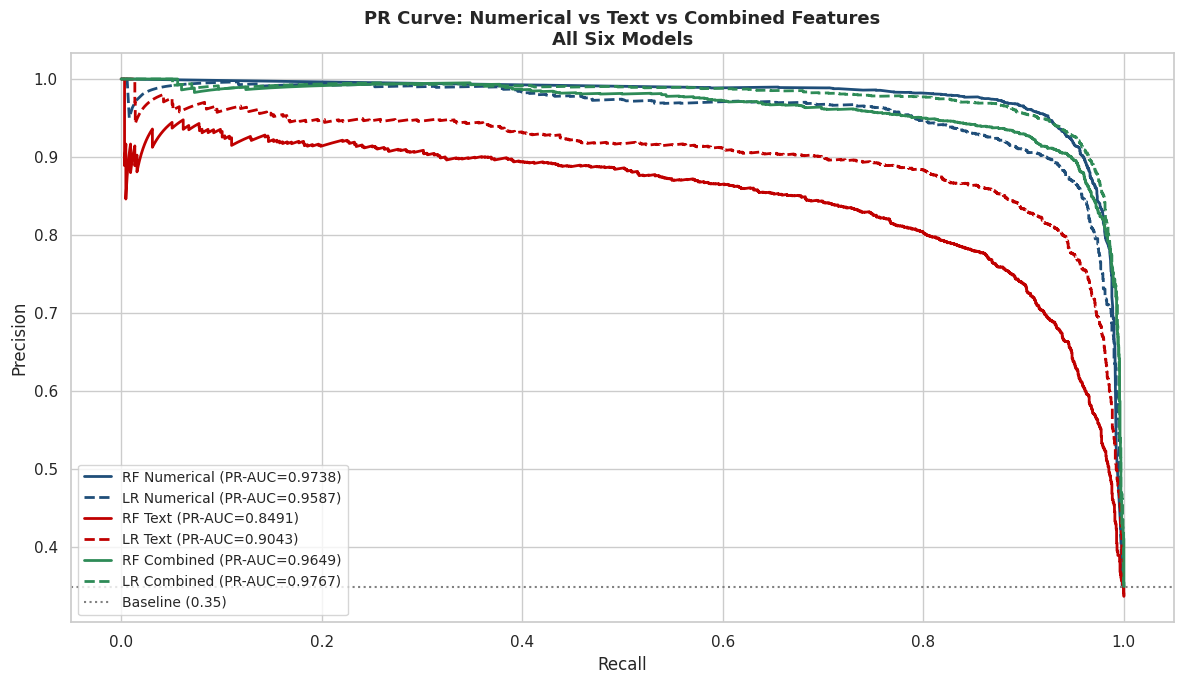

In [60]:
# ============================================================
# PART 4c: Cell 23 — PR Curve All Six Models
# ============================================================

plt.figure(figsize=(12, 7))

plot_models = {
    'RF Numerical':  ('#1F4E79', '-',  y_test,      rf_prob),
    'LR Numerical':  ('#1F4E79', '--', y_test,      lr_prob),
    'RF Text':       ('#C00000', '-',  y_text_test, rf_text_prob),
    'LR Text':       ('#C00000', '--', y_text_test, lr_text_prob),
    'RF Combined':   ('#2E8B57', '-',  y_comb_test, rf_comb_prob),
    'LR Combined':   ('#2E8B57', '--', y_comb_test, lr_comb_prob),
}

for name, (color, style, y_true, prob) in plot_models.items():
    prec, rec, _ = precision_recall_curve(y_true, prob)
    auc = average_precision_score(y_true, prob)
    plt.plot(rec, prec, color=color, linestyle=style,
             linewidth=2, label=f'{name} (PR-AUC={auc:.4f})')

baseline = y_comb_test.sum() / len(y_comb_test)
plt.axhline(y=baseline, color='grey', linestyle=':',
            linewidth=1.5, label=f'Baseline ({baseline:.2f})')

plt.title('PR Curve: Numerical vs Text vs Combined Features\nAll Six Models',
          fontsize=13, fontweight='bold')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(fontsize=10, loc='lower left')
plt.tight_layout()
plt.show()

In [61]:
# ============================================================
# PART 4c: Cell 24 — Feature Dominance Calculation
# ============================================================

num_feature_names = list(feature_cols)
cat_feature_names = list(df_encoded.columns)
text_feature_names = list(tfidf_combined.get_feature_names_out())
feature_names = num_feature_names + cat_feature_names + text_feature_names

print(f"Feature counts — Numerical: {len(num_feature_names)} | "
      f"Categorical: {len(cat_feature_names)} | "
      f"Text: {len(text_feature_names)} | "
      f"Total: {len(feature_names)}")
print(f"RF importances: {len(rf_combined.feature_importances_)}")

importances = pd.Series(
    rf_combined.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

num_imp = importances[importances.index.isin(num_feature_names)].sum()
cat_imp = importances[importances.index.isin(cat_feature_names)].sum()
txt_imp = importances[~importances.index.isin(num_feature_names + cat_feature_names)].sum()

print(f"\nNumerical:   {num_imp*100:.1f}%")
print(f"Categorical: {cat_imp*100:.1f}%")
print(f"Text:        {txt_imp*100:.1f}%")

Feature counts — Numerical: 7 | Categorical: 11 | Text: 5000 | Total: 5018
RF importances: 5018

Numerical:   44.4%
Categorical: 1.4%
Text:        54.3%


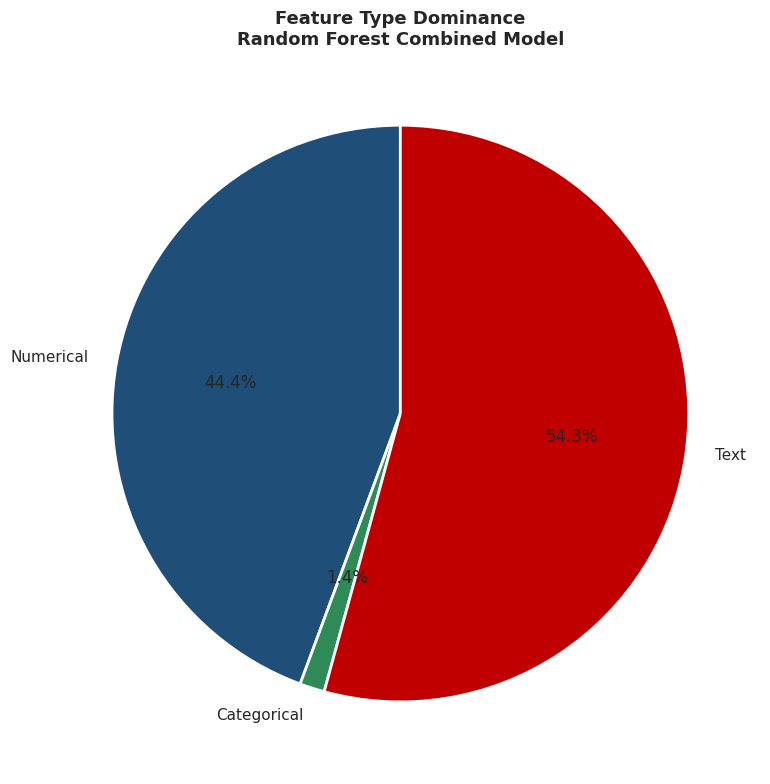

In [62]:
# ============================================================
# PART 4c: Cell 25 — Feature Type Dominance Pie Chart
# ============================================================

plt.figure(figsize=(8, 8))
plt.pie(
    [num_imp, cat_imp, txt_imp],
    labels=['Numerical', 'Categorical', 'Text'],
    colors=['#1F4E79', '#2E8B57', '#C00000'],
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
plt.title('Feature Type Dominance\nRandom Forest Combined Model',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

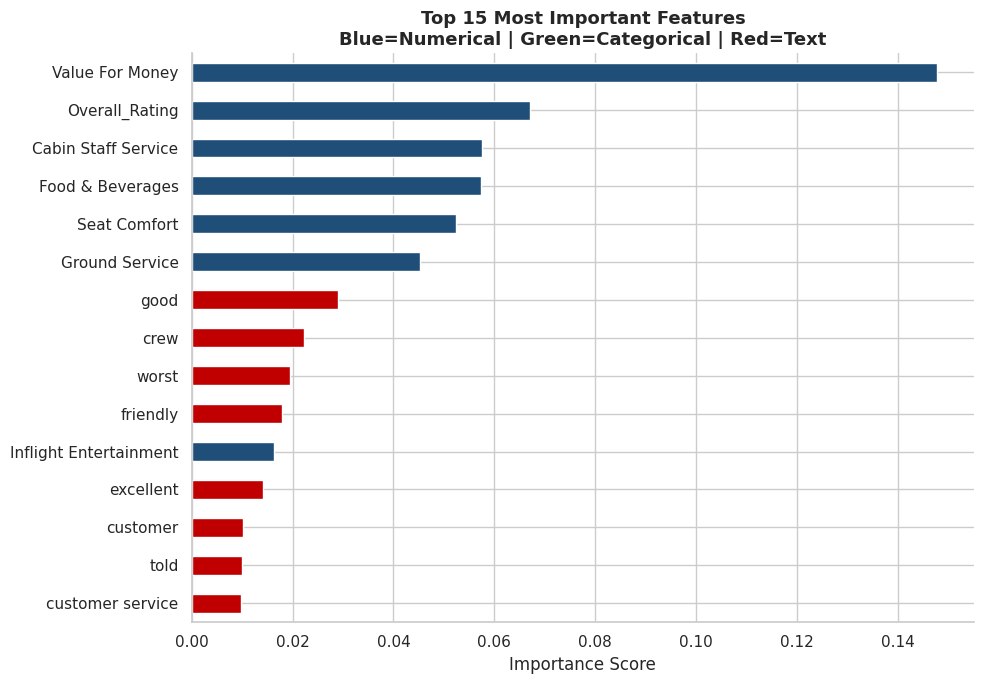


Top 5 numerical:
Value For Money        0.1478
Overall_Rating         0.0671
Cabin Staff Service    0.0575
Food & Beverages       0.0573
Seat Comfort           0.0523
dtype: float64

Top 5 categorical:
Type Of Traveller_Unknown    0.0074
Seat Type_Unknown            0.0030
Seat Type_Business Class     0.0018
Seat Type_Economy Class      0.0012
Verified                     0.0002
dtype: float64

Top 5 text:
good         0.0290
crew         0.0222
worst        0.0194
friendly     0.0179
excellent    0.0141
dtype: float64


In [63]:
# ============================================================
# PART 4c: Cell 26 — Top 15 Features Bar Chart
# ============================================================

top15 = importances.head(15).sort_values()
colors = ['#1F4E79' if f in num_feature_names
          else '#2E8B57' if f in cat_feature_names
          else '#C00000' for f in top15.index]

plt.figure(figsize=(10, 7))
top15.plot(kind='barh', color=colors, edgecolor='white')
plt.title('Top 15 Most Important Features\nBlue=Numerical | Green=Categorical | Red=Text',
          fontsize=13, fontweight='bold')
plt.xlabel('Importance Score')
plt.spines = plt.gca()
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

print("\nTop 5 numerical:")
print(importances[importances.index.isin(num_feature_names)].head(5).round(4))
print("\nTop 5 categorical:")
print(importances[importances.index.isin(cat_feature_names)].head(5).round(4))
print("\nTop 5 text:")
print(importances[~importances.index.isin(
    num_feature_names + cat_feature_names)].head(5).round(4))

In [64]:
# ============================================================
# PART 4c: Cell 25 — Failure Analysis
# ============================================================

# Find cases where combined model underperforms numerical model
df_comb_eval = df_combined.copy().reset_index(drop=True)

# Get test indices
test_size = len(y_comb_test)
df_test_eval = df_comb_eval.iloc[-test_size:].copy()
df_test_eval['RF_Comb_Pred'] = rf_comb_pred
df_test_eval['RF_Comb_Prob'] = rf_comb_prob
df_test_eval['Actual'] = y_comb_test.values

# Cases where model is confidently wrong
confident_wrong = df_test_eval[
    ((df_test_eval['RF_Comb_Pred'] != df_test_eval['Actual']) &
     ((df_test_eval['RF_Comb_Prob'] > 0.8) |
      (df_test_eval['RF_Comb_Prob'] < 0.2)))
]

print("=" * 50)
print("FAILURE ANALYSIS")
print("=" * 50)
print(f"Total test cases: {len(df_test_eval)}")
print(f"Confidently wrong predictions: {len(confident_wrong)}")
print(f"({len(confident_wrong)/len(df_test_eval)*100:.1f}% of test set)")

print("\nConfidently wrong — breakdown:")
print(confident_wrong.groupby(['Actual', 'RF_Comb_Pred']).size())

print("\nSample confidently wrong cases:")
for _, row in confident_wrong.head(3).iterrows():
    print(f"\nActual: {int(row['Actual'])} | "
          f"Predicted: {int(row['RF_Comb_Pred'])} | "
          f"Confidence: {row['RF_Comb_Prob']:.3f}")
    print(f"Review: {str(row['Review_Cleaned'])[:200]}")
    print("-" * 50)

FAILURE ANALYSIS
Total test cases: 6699
Confidently wrong predictions: 9
(0.1% of test set)

Confidently wrong — breakdown:
Actual  RF_Comb_Pred
0       1               4
1       0               5
dtype: int64

Sample confidently wrong cases:

Actual: 1 | Predicted: 0 | Confidence: 0.181
Review: flew ottawa halifax wife want acknowledge fantastic care received employee porter airline helped much difficult moment airport halifax agent also took great care change ticket could suit medical condi
--------------------------------------------------

Actual: 1 | Predicted: 0 | Confidence: 0.192
Review: morning april wife daniele scheduled depart dominica san juan silver airway flight scheduled depart san juan connection philadelphia montreal final destination phl connection pm plenty time hour san j
--------------------------------------------------

Actual: 1 | Predicted: 0 | Confidence: 0.190
Review: tame flight cancellation departed late jfk announced sending hotel quito since losing conne